### 🔹 Modeling

In [ ]:
import pandas as pd
import numpy as np
import joblib
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, make_scorer
from sklearn import ensemble
import lightgbm as lgb
import xgboost as xgb
import catboost as cb
import warnings
import time
import seaborn as sns
import matplotlib.pyplot as plt

from sales_forecasting_project.utils import MeanEnsemble, BoolToIntImputer

pd.set_option('display.max_columns', None)
warnings.filterwarnings('ignore') 

In [22]:
train = pd.read_csv('Datasets/train.csv')
features = pd.read_csv('Datasets/features.csv')
stores = pd.read_csv('Datasets/stores.csv')
test = pd.read_csv('Datasets/test.csv')

In [23]:
feature_store = features.merge(stores, how='left', on = "Store")

feature_store['Date'] = pd.to_datetime(feature_store['Date'])
train['Date'] = pd.to_datetime(train['Date'])
test['Date'] = pd.to_datetime(test['Date'])

feature_store['Day'] = feature_store['Date'].dt.day
feature_store['Week'] = feature_store['Date'].dt.isocalendar().week
feature_store['Month'] = feature_store['Date'].dt.month
feature_store['Year'] = feature_store['Date'].dt.year

In [24]:
train_merged= pd.merge(train, feature_store, on=['Store', 'Date', 'IsHoliday'], how='left')
display(train_merged.head())

test_merged = pd.merge(test, feature_store, on=['Store', 'Date', 'IsHoliday'], how='left')
display(test_merged.head())

,Store,Dept,Date,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Type,Size,Day,Week,Month,Year
0,1,1,2010-02-05,24924.50,False,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,A,151315,5,5,2,2010
1,1,1,2010-02-12,46039.49,True,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,A,151315,12,6,2,2010
2,1,1,2010-02-19,41595.55,False,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,A,151315,19,7,2,2010
3,1,1,2010-02-26,19403.54,False,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,A,151315,26,8,2,2010
4,1,1,2010-03-05,21827.90,False,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,A,151315,5,9,3,2010


,Store,Dept,Date,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Type,Size,Day,Week,Month,Year
0,1,1,2012-11-02,False,55.32,3.386,6766.44,5147.70,50.82,3639.90,2737.42,223.462779,6.573,A,151315,2,44,11,2012
1,1,1,2012-11-09,False,61.24,3.314,11421.32,3370.89,40.28,4646.79,6154.16,223.481307,6.573,A,151315,9,45,11,2012
2,1,1,2012-11-16,False,52.92,3.252,9696.28,292.10,103.78,1133.15,6612.69,223.512911,6.573,A,151315,16,46,11,2012
3,1,1,2012-11-23,True,56.23,3.211,883.59,4.17,74910.32,209.91,303.32,223.561947,6.573,A,151315,23,47,11,2012
4,1,1,2012-11-30,False,52.34,3.207,2460.03,NaN,3838.35,150.57,6966.34,223.610984,6.573,A,151315,30,48,11,2012


In [25]:
train_merged['Days_to_Thansksgiving'] = (pd.to_datetime(train_merged["Year"].astype(str)+"-11-24", format="%Y-%m-%d") - pd.to_datetime(train_merged["Date"], format="%Y-%m-%d")).dt.days.astype(int)
train_merged['Days_to_Christmas'] = (pd.to_datetime(train_merged["Year"].astype(str)+"-12-24", format="%Y-%m-%d") - pd.to_datetime(train_merged["Date"], format="%Y-%m-%d")).dt.days.astype(int)

In [26]:
superbowl_dates = ['2010-02-12', '2011-02-11', '2012-02-10', '2013-02-08']
labor_dates = ['2010-09-10', '2011-09-09', '2012-09-07', '2013-09-06']
thanksgiving_dates = ['2010-11-26', '2011-11-25', '2012-11-23', '2013-11-29']
christmas_dates = ['2010-12-31', '2011-12-30', '2012-12-28', '2013-12-27']

train_merged['SuperBowlWeek'] = train_merged['Date'].isin(superbowl_dates).astype(int)
train_merged['LaborDay'] = train_merged['Date'].isin(labor_dates).astype(int)
train_merged['Thanksgiving'] = train_merged['Date'].isin(thanksgiving_dates).astype(int)
train_merged['Christmas'] = train_merged['Date'].isin(christmas_dates).astype(int)

In [27]:
test_merged['Days_to_Thansksgiving'] = (pd.to_datetime(test_merged["Year"].astype(str)+"-11-24", format="%Y-%m-%d") - pd.to_datetime(test_merged["Date"], format="%Y-%m-%d")).dt.days.astype(int)
test_merged['Days_to_Christmas'] = (pd.to_datetime(test_merged["Year"].astype(str)+"-12-24", format="%Y-%m-%d") - pd.to_datetime(test_merged["Date"], format="%Y-%m-%d")).dt.days.astype(int)

In [28]:
superbowl_dates = ['2010-02-12', '2011-02-11', '2012-02-10', '2013-02-08']
labor_dates = ['2010-09-10', '2011-09-09', '2012-09-07', '2013-09-06']
thanksgiving_dates = ['2010-11-26', '2011-11-25', '2012-11-23', '2013-11-29']
christmas_dates = ['2010-12-31', '2011-12-30', '2012-12-28', '2013-12-27']

test_merged['SuperBowlWeek'] = test_merged['Date'].isin(superbowl_dates).astype(int)
test_merged['LaborDay'] = test_merged['Date'].isin(labor_dates).astype(int)
test_merged['Thanksgiving'] = test_merged['Date'].isin(thanksgiving_dates).astype(int)
test_merged['Christmas'] = test_merged['Date'].isin(christmas_dates).astype(int)

In [29]:
test_merged.head()

,Store,Dept,Date,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Type,Size,Day,Week,Month,Year,Days_to_Thansksgiving,Days_to_Christmas,SuperBowlWeek,LaborDay,Thanksgiving,Christmas
0,1,1,2012-11-02,False,55.32,3.386,6766.44,5147.70,50.82,3639.90,2737.42,223.462779,6.573,A,151315,2,44,11,2012,22,52,0,0,0,0
1,1,1,2012-11-09,False,61.24,3.314,11421.32,3370.89,40.28,4646.79,6154.16,223.481307,6.573,A,151315,9,45,11,2012,15,45,0,0,0,0
2,1,1,2012-11-16,False,52.92,3.252,9696.28,292.10,103.78,1133.15,6612.69,223.512911,6.573,A,151315,16,46,11,2012,8,38,0,0,0,0
3,1,1,2012-11-23,True,56.23,3.211,883.59,4.17,74910.32,209.91,303.32,223.561947,6.573,A,151315,23,47,11,2012,1,31,0,0,1,0
4,1,1,2012-11-30,False,52.34,3.207,2460.03,NaN,3838.35,150.57,6966.34,223.610984,6.573,A,151315,30,48,11,2012,-6,24,0,0,0,0


In [30]:
train_merged.isnull().sum()

Store                         0
Dept                          0
Date                          0
Weekly_Sales                  0
IsHoliday                     0
Temperature                   0
Fuel_Price                    0
MarkDown1                270889
MarkDown2                310322
MarkDown3                284479
MarkDown4                286603
MarkDown5                270138
CPI                           0
Unemployment                  0
Type                          0
Size                          0
Day                           0
Week                          0
Month                         0
Year                          0
Days_to_Thansksgiving         0
Days_to_Christmas             0
SuperBowlWeek                 0
LaborDay                      0
Thanksgiving                  0
Christmas                     0
dtype: int64

In [31]:
test_merged.isnull().sum()

Store                        0
Dept                         0
Date                         0
IsHoliday                    0
Temperature                  0
Fuel_Price                   0
MarkDown1                  149
MarkDown2                28627
MarkDown3                 9829
MarkDown4                12888
MarkDown5                    0
CPI                      38162
Unemployment             38162
Type                         0
Size                         0
Day                          0
Week                         0
Month                        0
Year                         0
Days_to_Thansksgiving        0
Days_to_Christmas            0
SuperBowlWeek                0
LaborDay                     0
Thanksgiving                 0
Christmas                    0
dtype: int64

In [32]:
train_merged.fillna(0, inplace = True)

test_merged['CPI'].fillna(test_merged['CPI'].mean(), inplace = True)
test_merged['Unemployment'].fillna(test_merged['Unemployment'].mean(), inplace = True)

test_merged.fillna(0, inplace = True)

In [33]:
train_merged.columns

Index(['Store', 'Dept', 'Date', 'Weekly_Sales', 'IsHoliday', 'Temperature',
       'Fuel_Price', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4',
       'MarkDown5', 'CPI', 'Unemployment', 'Type', 'Size', 'Day', 'Week',
       'Month', 'Year', 'Days_to_Thansksgiving', 'Days_to_Christmas',
       'SuperBowlWeek', 'LaborDay', 'Thanksgiving', 'Christmas'],
      dtype='object')

In [34]:
X = train_merged.drop(columns=['Date', 'Weekly_Sales'])
y = train_merged['Weekly_Sales']

X_test = test_merged.drop(columns=['Date'])

In [35]:
dummies = pd.get_dummies(X['Type'], prefix='Type', drop_first=False).astype(int)
X = X.drop(columns=['Type'])
X = pd.concat([X, dummies], axis=1)

X['IsHoliday'] = X['IsHoliday'].astype(int)

X.head(1)

,Store,Dept,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Size,Day,Week,Month,Year,Days_to_Thansksgiving,Days_to_Christmas,SuperBowlWeek,LaborDay,Thanksgiving,Christmas,Type_A,Type_B,Type_C
0,1,1,0,42.31,2.572,0.0,0.0,0.0,0.0,0.0,211.096358,8.106,151315,5,5,2,2010,292,322,0,0,0,0,1,0,0


In [36]:
dummies = pd.get_dummies(X_test['Type'], prefix='Type', drop_first=False).astype(int)
X_test = X_test.drop(columns=['Type'])
X_test = pd.concat([X_test, dummies], axis=1)

X_test['IsHoliday'] = X_test['IsHoliday'].astype(int)

X_test.head(1)

,Store,Dept,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Size,Day,Week,Month,Year,Days_to_Thansksgiving,Days_to_Christmas,SuperBowlWeek,LaborDay,Thanksgiving,Christmas,Type_A,Type_B,Type_C
0,1,1,0,55.32,3.386,6766.44,5147.7,50.82,3639.9,2737.42,223.462779,6.573,151315,2,44,11,2012,22,52,0,0,0,0,1,0,0


In [38]:
def weighted_mae_scorer(estimator, X, y):
    y_pred = estimator.predict(X)
    sample_weight = np.where(X['IsHoliday'], 5, 1)
    return -np.sum(sample_weight * np.abs(y - y_pred)) / np.sum(sample_weight)

def WMAE(y_true, y_pred, sample_weight=None):
    if sample_weight is None:
        sample_weight = np.ones_like(y_true)
    return np.sum(sample_weight * np.abs(y_true - y_pred)) / np.sum(sample_weight)

def RMSE(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

X_weights = np.where(X['IsHoliday'], 5, 1)

wmae_scorer = make_scorer(WMAE, greater_is_better=False)
rmse_scorer = make_scorer(RMSE, greater_is_better=False)

In [39]:
X_train, X_val, y_train, y_val, sw_train, sw_val = train_test_split(
    X, y, X_weights, test_size=0.2, random_state=42
)

In [40]:
models = {
    'LGBM': lgb.LGBMRegressor(random_state=0, verbose=-1, n_jobs=-1),
    'CatBoost': cb.CatBoostRegressor(random_state=0, verbose=False),
    'XGBoost': xgb.XGBRegressor(random_state=0, n_jobs=-1),
    'RandomTrees': ensemble.RandomForestRegressor(random_state=0, n_jobs=-1),
    'ExtraTrees': ensemble.ExtraTreesRegressor(random_state=0, n_jobs=-1)
}

for name, model in models.items():
    print(f"\n===== {name} =====")
     
    start = time.time()

    model.fit(X_train, y_train)
    
    end = time.time()

    y_pred = model.predict(X_val)

    wmae = WMAE(y_val, y_pred, sw_val)
    rmse = RMSE(y_val, y_pred)

    result = permutation_importance(
        model,
        X_val,
        y_val,
        n_repeats=10,
        random_state=42,
        scoring=weighted_mae_scorer
    )

    importances = (
        pd.DataFrame({
            'feature': X.columns,
            'importance_mean': result.importances_mean,
            'importance_std': result.importances_std
        })
        .sort_values('importance_mean', ascending=False)
    )

    print(f"{name} WMAE: {wmae:.4f}")
    print(f"{name} RMSE: {rmse:.4f}")
    print(f"{name} Train Time: {end-start:.4f}s")
    display(importances.head(10))


===== LGBM =====
LGBM WMAE: 4282.4505
LGBM RMSE: 6844.8975
LGBM Train Time: 0.6480s


,feature,importance_mean,importance_std
1,Dept,14036.765028,101.458085
12,Size,4797.417217,34.063436
0,Store,1540.744885,13.044551
10,CPI,472.229490,8.418247
24,Type_B,468.588506,8.303473
14,Week,303.092372,10.430701
13,Day,159.874967,3.830274
11,Unemployment,121.755757,2.268438
21,Thanksgiving,120.093033,4.524032
17,Days_to_Thansksgiving,117.660112,3.622491



===== CatBoost =====
CatBoost WMAE: 3306.1772
CatBoost RMSE: 5517.9832
CatBoost Train Time: 15.7736s


,feature,importance_mean,importance_std
1,Dept,15718.243235,104.676869
12,Size,5247.884418,24.314044
0,Store,1916.347437,15.068687
24,Type_B,924.351922,11.266108
10,CPI,888.194264,9.426009
17,Days_to_Thansksgiving,265.992517,6.072324
11,Unemployment,203.300994,2.558739
3,Temperature,169.801115,5.369346
13,Day,169.220358,2.255691
23,Type_A,164.971543,3.505415



===== XGBoost =====
XGBoost WMAE: 3129.4389
XGBoost RMSE: 5264.9948
XGBoost Train Time: 0.7889s


,feature,importance_mean,importance_std
1,Dept,15900.833573,103.205829
12,Size,5395.214812,34.304456
0,Store,2445.329474,18.621618
10,CPI,1148.114091,7.396451
14,Week,540.993152,8.085893
24,Type_B,532.453027,9.085684
11,Unemployment,319.885230,6.952784
17,Days_to_Thansksgiving,243.496272,4.631249
13,Day,242.501125,4.841568
3,Temperature,163.805633,6.401237



===== RandomTrees =====
RandomTrees WMAE: 1501.0325
RandomTrees RMSE: 3400.6493
RandomTrees Train Time: 43.9662s


,feature,importance_mean,importance_std
1,Dept,17697.362982,126.584073
12,Size,7308.369743,40.964090
0,Store,2762.421735,16.975827
10,CPI,1512.924456,15.114576
24,Type_B,659.046566,9.374393
3,Temperature,462.820803,12.733907
11,Unemployment,423.774346,5.961156
17,Days_to_Thansksgiving,359.736050,7.485896
18,Days_to_Christmas,357.527118,5.645287
14,Week,327.611759,6.960871



===== ExtraTrees =====
ExtraTrees WMAE: 1514.8314
ExtraTrees RMSE: 3397.8507
ExtraTrees Train Time: 27.1795s


,feature,importance_mean,importance_std
1,Dept,17700.769776,125.728212
12,Size,5998.656828,28.379836
0,Store,2150.953137,12.167282
23,Type_A,1704.753260,18.093792
10,CPI,1550.360607,20.392877
24,Type_B,694.092375,9.709379
11,Unemployment,231.984786,3.248556
14,Week,229.627371,4.407652
18,Days_to_Christmas,215.280432,4.475764
17,Days_to_Thansksgiving,210.481707,3.628020


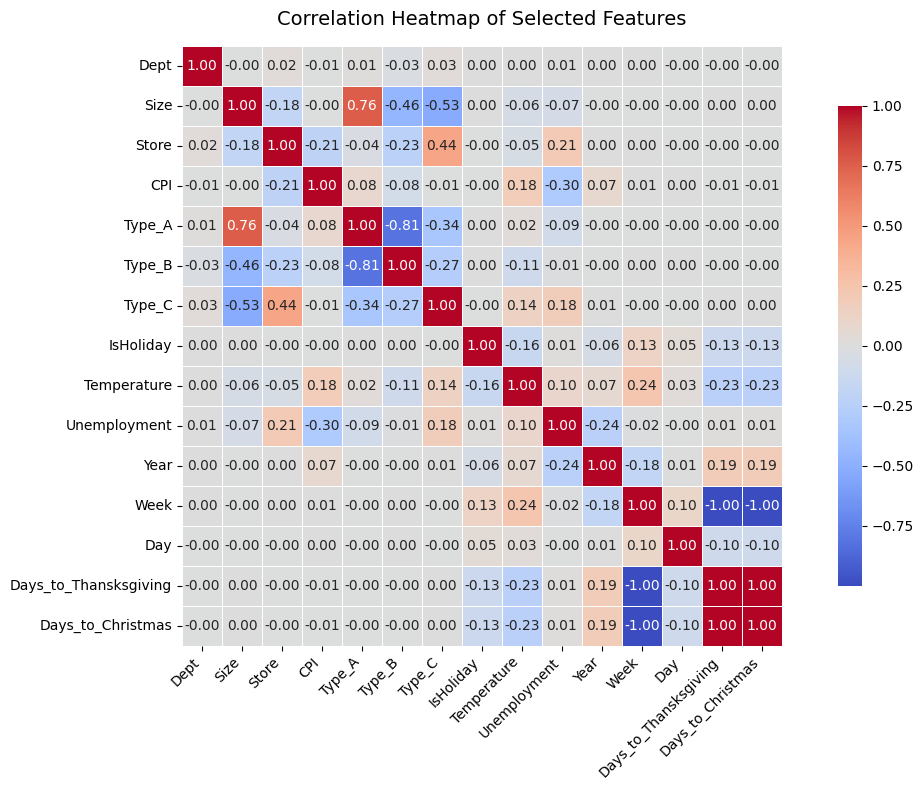

In [41]:
selected_features = [
'Dept','Size','Store','CPI','Type_A', 'Type_B', 'Type_C', 'IsHoliday', 
'Temperature','Unemployment', 'Year', 'Week', 'Day', 'Days_to_Thansksgiving', 'Days_to_Christmas'
]

corr_df = X[selected_features].copy()

corr_matrix = corr_df.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})

plt.title("Correlation Heatmap of Selected Features", fontsize=14, pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [42]:
selected_features = ['Store','Dept','IsHoliday','Size','Type_A', 'Type_B', 'Type_C', 'Year', 'Week', 'Day']

In [43]:
X_pruned = X[selected_features]
X_pruned_train = X_train[selected_features]
X_pruned_val = X_val[selected_features]

In [44]:
scoring = {
    'RMSE': rmse_scorer,
    'WMAE': wmae_scorer
}

In [45]:
cv = KFold(n_splits=5, shuffle=True, random_state=0)

In [46]:
rfm_grid = ensemble.RandomForestRegressor(random_state=0, verbose=0)

param_grid = {
    'n_estimators': [30, 60],
    'max_depth': [25, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
}

grid = GridSearchCV(
    estimator=rfm_grid,
    param_grid=param_grid,
    cv=cv,
    scoring=scoring,
    refit='WMAE',
    n_jobs=-1,
    verbose=2
)

print("Running Grid Search for RandomForest...")
grid.fit(X_pruned, y, sample_weight=X_weights)

results = pd.DataFrame(grid.cv_results_)

best_wmae_row = results.loc[results['mean_test_WMAE'].idxmax()]

display(best_wmae_row[['mean_test_WMAE', 'mean_test_RMSE']])
print("Best Params:", best_wmae_row['params'])

Running Grid Search for RandomForest...
Fitting 5 folds for each of 16 candidates, totalling 80 fits


mean_test_WMAE   -1394.037705
mean_test_RMSE   -3035.602199
Name: 9, dtype: object

Best Params: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 60}


In [47]:
rfm = ensemble.RandomForestRegressor(max_depth=None, min_samples_leaf=1, min_samples_split=2, n_estimators=60, n_jobs=-1)
etrm = ensemble.ExtraTreesRegressor(max_depth=None, min_samples_leaf=1, min_samples_split=2, n_estimators=60, n_jobs=-1)

In [48]:
rfm.fit(X_pruned_train, y_train)
rfm_pruned_preds = rfm.predict(X_pruned_val)

etrm.fit(X_pruned_train, y_train)
etrm_pruned_preds = etrm.predict(X_pruned_val)

print("RFM Pruned Features WMAE:", WMAE(y_val, rfm_pruned_preds, sw_val))
print("ETRM Pruned Features WMAE:", WMAE(y_val, etrm_pruned_preds, sw_val))

RFM Pruned Features WMAE: 1419.7846619033542
ETRM Pruned Features WMAE: 1509.1935733433095


In [49]:
rfm.fit(X, y)
rfm_all_preds = rfm.predict(X_test)

etrm.fit(X, y)
etrm_all_preds = etrm.predict(X_test)

In [50]:
rfm.fit(X_pruned, y)
rfm_pruned_preds = rfm.predict(X_test[selected_features])

etrm.fit(X_pruned, y)
etrm_pruned_preds = etrm.predict(X_test[selected_features])

In [51]:
submission = pd.DataFrame()
submission['Id'] = test_merged.apply(lambda x : f"{x['Store']}_{x['Dept']}_{x['Date'].strftime('%Y-%m-%d')}", axis=1)
print(submission.shape)
submission.head()

(115064, 1)


,Id
0,1_1_2012-11-02
1,1_1_2012-11-09
2,1_1_2012-11-16
3,1_1_2012-11-23
4,1_1_2012-11-30


In [ ]:
submission['Weekly_Sales'] = rfm_all_preds
submission.to_csv("./submissions/rfm_all_submission.csv", index=False)

submission['Weekly_Sales'] = etrm_all_preds
submission.to_csv("./submissions/etrm_all_submission.csv", index=False)

submission['Weekly_Sales'] = rfm_pruned_preds
submission.to_csv("./submissions/rfm_pruned_submission.csv", index=False)

submission['Weekly_Sales'] = etrm_pruned_preds
submission.to_csv("./submissions/etrm_pruned_submission.csv", index=False)

In [52]:
submission['Weekly_Sales'] = (rfm_pruned_preds + etrm_pruned_preds) / 2
submission.to_csv("./submissions/mean_ensemble_submission.csv", index=False)

In [76]:
features = ['Store','Dept','IsHoliday','Size', 'Type', 'Year', 'Week', 'Day']

categorical_features = [feature for feature in features if train_merged[feature].dtype == 'object']
boolean_features = [feature for feature in features if train_merged[feature].dtype == 'bool']
numerical_features = [feature for feature in features if feature not in categorical_features + boolean_features]

print(categorical_features)
print(boolean_features)
print(numerical_features)

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

boolean_transformer = Pipeline([
    ('bool_to_int', BoolToIntImputer()),
    ('imputer', SimpleImputer(strategy='most_frequent'))
])

numerical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='mean'))
])

preprocessor = ColumnTransformer([
    ('cat', categorical_transformer, categorical_features),
    ('bool', boolean_transformer, boolean_features),
    ('num', numerical_transformer, numerical_features)
])

['Type']
['IsHoliday']
['Store', 'Dept', 'Size', 'Year', 'Week', 'Day']


In [79]:
rfm = ensemble.RandomForestRegressor(max_depth=None, min_samples_leaf=1, min_samples_split=2, n_estimators=60, n_jobs=-1)
etrm = ensemble.ExtraTreesRegressor(max_depth=None, min_samples_leaf=1, min_samples_split=2, n_estimators=60, n_jobs=-1)

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', MeanEnsemble(models=[rfm, etrm]))
])

pipeline.fit(train_merged[features], y)

mean_ensemble_preds = pipeline.predict(test_merged[features])

submission['Weekly_Sales'] = mean_ensemble_preds
submission.to_csv("./submissions/mean_ensemble_submission.csv", index=False)

joblib.dump(pipeline, "./sales_forecasting_project/models/mean_ensemble_model.joblib")

['./sales_forecasting_project/models/mean_ensemble_model.joblib']

---
# 🔷 Phase 1 — Feature Reduction, Feature Selection & Classification (AID427)

This section is **self-contained**: it reloads the raw data, so it can be run on its own (Kernel → Restart, then run from here).

**Task framing.** The cover sheet asks for classification metrics (confusion matrix, precision, recall, ROC-AUC) and for LDA, which all need class labels.
`Weekly_Sales` is continuous, so we turn it into a **3-class problem — Low / Medium / High weekly sales** — using the training-data tertiles (33rd and 67th percentiles).
The earlier regression models above are left unchanged.

| Cover-sheet item | Section |
|---|---|
| Problem introduction / dataset description | 1, 2 |
| Data analysis, preprocessing, visualization before & after reduction and clustering | 3, 6 |
| Linear reduction (PCA, LDA, SVD) | 4 |
| Non-linear reduction (Kernel PCA, SNE, t-SNE, UMAP, metric & non-metric MDS, Isomap, LLE) | 5 |
| Feature selection: filter / wrapper / embedded / GA & metaheuristics | 7 |
| Model implementation | 8 |
| Evaluation: 80/20 split, k-fold CV, confusion matrix, accuracy, error rate, precision, recall, F1, ROC-AUC, over/under-fitting | 9 |
| Comparison with related work | 10 |

In [1]:
# If a package is missing, uncomment and run:
# %pip install umap-learn lightgbm xgboost seaborn

import os, gc, time, json, inspect, warnings
from sklearn.base import clone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import xgboost as xgb
import umap

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score,
                                     cross_validate, learning_curve, validation_curve)
from sklearn.decomposition import PCA, TruncatedSVD, KernelPCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.manifold import TSNE, MDS, Isomap, LocallyLinearEmbedding, trustworthiness
from sklearn.cluster import KMeans
from sklearn.feature_selection import (VarianceThreshold, f_classif, chi2, mutual_info_classif,
                                       SequentialFeatureSelector, RFE)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, roc_curve, auc, silhouette_score,
                             adjusted_rand_score, normalized_mutual_info_score)
from sklearn.preprocessing import label_binarize

warnings.filterwarnings("ignore")
RS = 42
np.random.seed(RS)
FIG_DIR, RES_DIR = "figures/phase1", "results"
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(RES_DIR, exist_ok=True)
RESULTS = {}                      # every number used in the report is stored here
CLASS_NAMES = ["Low", "Medium", "High"]
PALETTE = {"Low": "#4C72B0", "Medium": "#DD8452", "High": "#55A868"}
sns.set_theme(style="whitegrid", context="notebook")

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

# version-safe constructors (scikit-learn renamed some arguments in 1.8)
def make_lr(l1_ratio=0.0, C=1.0, solver="saga", max_iter=2000):
    params = inspect.signature(LogisticRegression).parameters
    if params["penalty"].default == "deprecated":
        return LogisticRegression(C=C, l1_ratio=l1_ratio, solver=solver, max_iter=max_iter, random_state=RS)
    pen = "l1" if l1_ratio == 1 else ("l2" if l1_ratio == 0 else "elasticnet")
    kw = {"l1_ratio": l1_ratio} if pen == "elasticnet" else {}
    return LogisticRegression(penalty=pen, C=C, solver=solver, max_iter=max_iter, random_state=RS, **kw)

def make_mds(metric=True, **kw):
    params = inspect.signature(MDS).parameters
    key = "metric_mds" if "metric_mds" in params else "metric"
    if "init" in params: kw.setdefault("init", "random")
    return MDS(n_components=2, random_state=RS, **{key: metric}, **kw)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Problem Introduction

Walmart must plan stock, staff and promotions for **45 stores × ~81 departments** every week.
Exact weekly-sales forecasting is noisy, but many operational decisions only need to know whether a department-week will be a **low-, medium- or high-volume week**.
We therefore study a **3-class weekly-sales-level classification** problem and use it to compare:

* linear and non-linear **feature-reduction** methods (how well they preserve the class structure),
* **feature-selection** families (filter, wrapper, embedded, and metaheuristics: GA, Binary PSO and Simulated Annealing),
* nine **classifiers**, evaluated with an 80/20 hold-out split and 5-fold cross-validation.

## 2. Dataset Description

Kaggle *Walmart Recruiting – Store Sales Forecasting* (Feb 2010 – Oct 2012):

* `train.csv` — 421,570 rows: `Store`, `Dept`, `Date`, `Weekly_Sales`, `IsHoliday`
* `features.csv` — store-week context: `Temperature`, `Fuel_Price`, `MarkDown1–5`, `CPI`, `Unemployment`
* `stores.csv` — store `Type` (A/B/C) and `Size`

The cell below merges the files and **measures the noise** in the data (the cover sheet asks for a difficult, noisy dataset).

In [2]:
train_raw = pd.read_csv("Datasets/train.csv", parse_dates=["Date"])
feat_raw  = pd.read_csv("Datasets/features.csv", parse_dates=["Date"])
stores_raw = pd.read_csv("Datasets/stores.csv")

df = (train_raw.merge(feat_raw.drop(columns="IsHoliday"), on=["Store", "Date"], how="left")
               .merge(stores_raw, on="Store", how="left"))
print("Merged shape:", df.shape)

md_cols = [f"MarkDown{i}" for i in range(1, 6)]
q1, q3 = df["Weekly_Sales"].quantile([0.25, 0.75])
iqr_out = ((df["Weekly_Sales"] < q1 - 1.5 * (q3 - q1)) | (df["Weekly_Sales"] > q3 + 1.5 * (q3 - q1))).sum()

noise = pd.DataFrame({
    "Issue": ["Negative weekly sales (returns)", "Weekly-sales outliers (1.5×IQR)",
              *[f"{c} missing" for c in md_cols],
              "Negative MarkDown values", "Holiday weeks (class-imbalance in time)",
              "Skewness of Weekly_Sales"],
    "Value": [ (df["Weekly_Sales"] < 0).sum(), iqr_out,
              *[df[c].isna().sum() for c in md_cols],
              int((df[md_cols] < 0).sum().sum()), int(df["IsHoliday"].sum()),
              round(df["Weekly_Sales"].skew(), 2)],
})
noise["% of rows"] = np.where(noise["Issue"].str.startswith("Skew"), np.nan,
                              (noise["Value"] / len(df) * 100).round(2))
display(noise)

RESULTS["data"] = {
    "n_rows": int(len(df)), "n_stores": int(df["Store"].nunique()), "n_depts": int(df["Dept"].nunique()),
    "date_min": str(df["Date"].min().date()), "date_max": str(df["Date"].max().date()),
    "neg_sales": int((df["Weekly_Sales"] < 0).sum()), "iqr_outliers": int(iqr_out),
    "md_missing_pct": {c: round(df[c].isna().mean() * 100, 2) for c in md_cols},
    "neg_markdowns": int((df[md_cols] < 0).sum().sum()), "holiday_rows": int(df["IsHoliday"].sum()),
    "sales_skew": round(float(df["Weekly_Sales"].skew()), 3),
    "sales_desc": df["Weekly_Sales"].describe().round(2).to_dict(),
}

Merged shape: (421570, 16)


,Issue,Value,% of rows
0,Negative weekly sales (returns),1285.00,0.30
1,Weekly-sales outliers (1.5×IQR),35521.00,8.43
2,MarkDown1 missing,270889.00,64.26
3,MarkDown2 missing,310322.00,73.61
4,MarkDown3 missing,284479.00,67.48
5,MarkDown4 missing,286603.00,67.98
6,MarkDown5 missing,270138.00,64.08
7,Negative MarkDown values,1568.00,0.37
8,Holiday weeks (class-imbalance in time),29661.00,7.04
9,Skewness of Weekly_Sales,3.26,NaN


In [3]:
# ---- Target: 3 sales levels from tertiles of Weekly_Sales
t1, t2 = df["Weekly_Sales"].quantile([1/3, 2/3])
df["Sales_Class"] = np.select([df["Weekly_Sales"] <= t1, df["Weekly_Sales"] <= t2], [0, 1], 2)
print(f"Low ≤ {t1:,.2f} < Medium ≤ {t2:,.2f} < High")
display(df["Sales_Class"].map(dict(enumerate(CLASS_NAMES))).value_counts().to_frame("rows"))
RESULTS["target"] = {"t1": round(float(t1), 2), "t2": round(float(t2), 2),
                     "counts": df["Sales_Class"].value_counts().sort_index().tolist()}

Low ≤ 3,521.78 < Medium ≤ 14,599.76 < High


,rows
Sales_Class,
Low,140524
High,140523
Medium,140523


## 3. Data Analysis and Preprocessing

Steps (all decided from the training data only):

1. **Missing MarkDowns** → 0 (no promotion that week) plus a `MarkDown_Available` flag.
2. **Negative MarkDowns** (data-entry noise) → clipped to 0; MarkDown tails winsorized at the 99.5th percentile.
3. **Calendar features**: `Year`, `Month`, `Week`, `Day`, days to Thanksgiving / Christmas, Super Bowl and Labor Day flags.
4. **Store type** one-hot encoded; `IsHoliday` cast to int.
5. Negative sales are kept (they are real returns) and fall in the *Low* class.

In [4]:
thanks = {2010: "2010-11-26", 2011: "2011-11-25", 2012: "2012-11-23"}
xmas   = {2010: "2010-12-31", 2011: "2011-12-30", 2012: "2012-12-28"}
superbowl = pd.to_datetime(["2010-02-12", "2011-02-11", "2012-02-10"])
labor     = pd.to_datetime(["2010-09-10", "2011-09-09", "2012-09-07"])

df["Year"], df["Month"] = df["Date"].dt.year, df["Date"].dt.month
df["Week"], df["Day"] = df["Date"].dt.isocalendar().week.astype(int), df["Date"].dt.day
df["Days_to_Thanksgiving"] = (pd.to_datetime(df["Year"].map(thanks)) - df["Date"]).dt.days
df["Days_to_Christmas"]    = (pd.to_datetime(df["Year"].map(xmas)) - df["Date"]).dt.days
df["SuperBowl"] = df["Date"].isin(superbowl).astype(int)
df["LaborDay"]  = df["Date"].isin(labor).astype(int)

df["MarkDown_Available"] = df[md_cols].notna().any(axis=1).astype(int)
df[md_cols] = df[md_cols].fillna(0).clip(lower=0)
for c in md_cols:
    df[c] = df[c].clip(upper=df[c].quantile(0.995))
df["IsHoliday"] = df["IsHoliday"].astype(int)
df = pd.concat([df, pd.get_dummies(df["Type"], prefix="Type").astype(int)], axis=1)

FEATURES = ["Store", "Dept", "Size", "Type_A", "Type_B", "Type_C", "IsHoliday",
            "Temperature", "Fuel_Price", *md_cols, "MarkDown_Available", "CPI", "Unemployment",
            "Year", "Month", "Week", "Day", "Days_to_Thanksgiving", "Days_to_Christmas",
            "SuperBowl", "LaborDay"]
print(len(FEATURES), "features; remaining NaNs:", int(df[FEATURES].isna().sum().sum()))
RESULTS["features"] = FEATURES

25 features; remaining NaNs: 0


### 3.1 Visualization *before* reduction

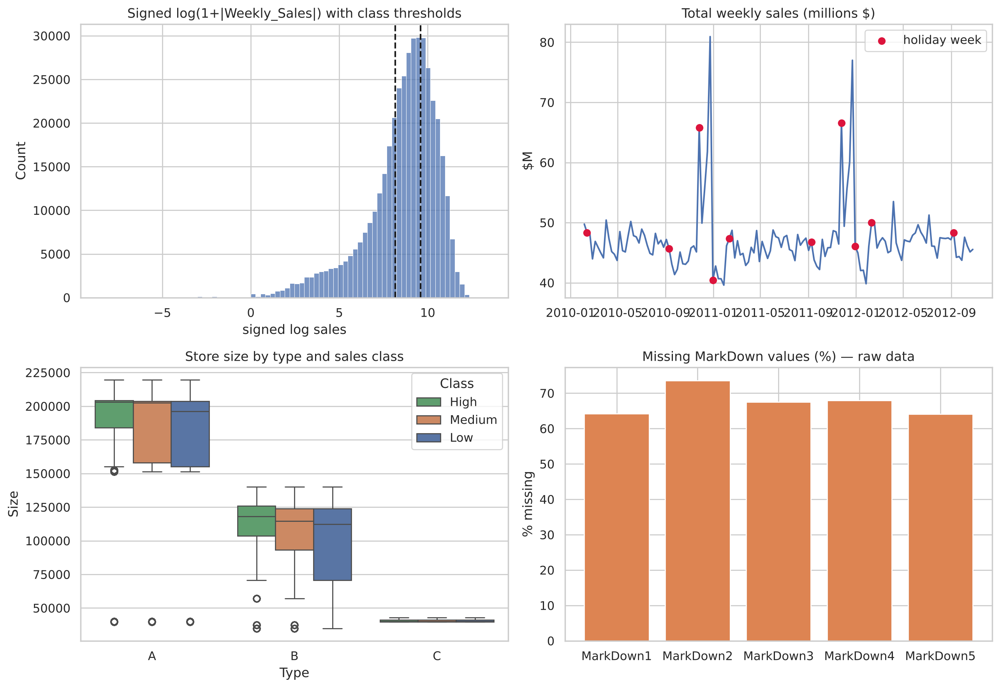

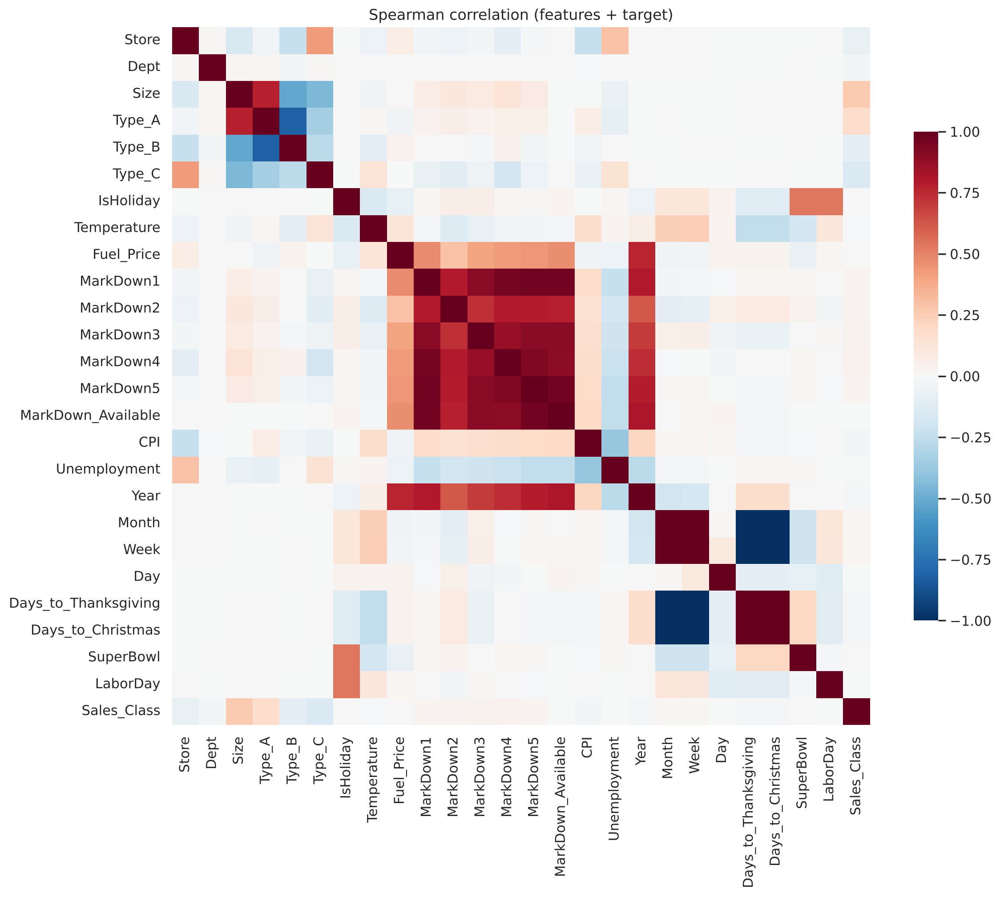

In [5]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
sns.histplot(np.sign(df["Weekly_Sales"]) * np.log1p(df["Weekly_Sales"].abs()), bins=80, ax=ax[0, 0], color="#4C72B0")
for t in (t1, t2): ax[0, 0].axvline(np.log1p(t), color="k", ls="--")
ax[0, 0].set(title="Signed log(1+|Weekly_Sales|) with class thresholds", xlabel="signed log sales")

wk = df.groupby("Date")["Weekly_Sales"].sum() / 1e6
ax[0, 1].plot(wk.index, wk.values, color="#4C72B0")
hol = df.loc[df["IsHoliday"] == 1, "Date"].unique()
ax[0, 1].scatter(hol, wk.loc[hol], color="crimson", zorder=3, label="holiday week")
ax[0, 1].set(title="Total weekly sales (millions $)", ylabel="$M"); ax[0, 1].legend()

sns.boxplot(data=df.assign(Class=df["Sales_Class"].map(dict(enumerate(CLASS_NAMES)))),
            x="Type", y="Size", hue="Class", palette=PALETTE, ax=ax[1, 0], order=["A", "B", "C"])
ax[1, 0].set(title="Store size by type and sales class")

miss = pd.Series(RESULTS["data"]["md_missing_pct"])
ax[1, 1].bar(miss.index, miss.values, color="#DD8452")
ax[1, 1].set(title="Missing MarkDown values (%) — raw data", ylabel="% missing")
savefig("01_eda_overview")

plt.figure(figsize=(12, 10))
corr = df[FEATURES + ["Sales_Class"]].corr(method="spearman")
sns.heatmap(corr, cmap="RdBu_r", center=0, square=True, cbar_kws={"shrink": .7}, xticklabels=True, yticklabels=True)
plt.title("Spearman correlation (features + target)")
savefig("02_correlation")
RESULTS["corr_with_target"] = corr["Sales_Class"].drop("Sales_Class").round(3).sort_values(key=abs, ascending=False).to_dict()

### 3.2 Samples and train/test split

* **Modelling sample**: 100,000 rows, stratified by class, then split **80% train / 20% test** (stratified).
  Every feature-selection method sees **only the training part** — no test leakage.
* **Visualization sample**: 3,000 training rows (manifold methods are O(n²) in memory/time).

train (80000, 25) test (20000, 25)
Baseline kNN on all 25 standardized features: 0.412


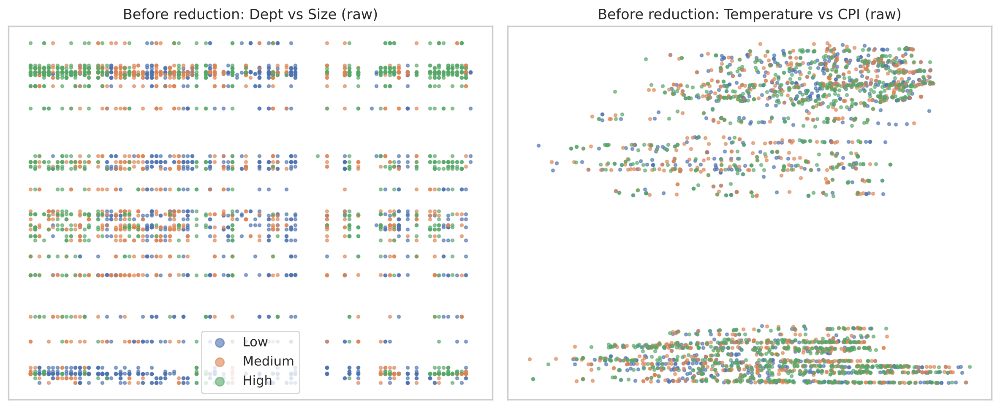

In [6]:
model_df, _ = train_test_split(df, train_size=100_000, stratify=df["Sales_Class"], random_state=RS)
X_all, y_all = model_df[FEATURES].astype(float), model_df["Sales_Class"].values
X_tr, X_te, y_tr, y_te = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, random_state=RS)
print("train", X_tr.shape, "test", X_te.shape)

viz_idx = np.random.RandomState(RS).choice(len(X_tr), 3000, replace=False)
X_viz, y_viz = X_tr.iloc[viz_idx], y_tr[viz_idx]
Xs_viz = StandardScaler().fit_transform(X_viz)
y_viz_lbl = pd.Series(y_viz).map(dict(enumerate(CLASS_NAMES))).values
RESULTS["split"] = {"model_n": len(X_all), "train_n": len(X_tr), "test_n": len(X_te), "viz_n": len(X_viz)}

def scatter2d(Z, title, ax, labels=y_viz_lbl, s=6):
    for c in CLASS_NAMES:
        m = labels == c
        ax.scatter(Z[m, 0], Z[m, 1], s=s, alpha=.6, label=c, color=PALETTE[c])
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])

EMB, EMB_STATS = {}, []
def embed_eval(name, Z, X_ref=Xs_viz, y=y_viz, secs=None):
    n = len(Z)
    knn = cross_val_score(KNeighborsClassifier(5), Z, y, cv=5).mean()
    tw = trustworthiness(X_ref[:n], Z, n_neighbors=10)
    sil = silhouette_score(Z, y)
    EMB[name] = Z
    EMB_STATS.append({"Method": name, "kNN acc (5-fold)": knn, "Trustworthiness": tw,
                      "Silhouette (true classes)": sil, "Time (s)": secs, "n": n})
    print(f"{name:<16} kNN={knn:.3f}  trust={tw:.3f}  silhouette={sil:.3f}  time={secs:.1f}s")

# reference: kNN directly on the 25 standardized features (no reduction)
base_knn = cross_val_score(KNeighborsClassifier(5), Xs_viz, y_viz, cv=5).mean()
print(f"Baseline kNN on all {len(FEATURES)} standardized features: {base_knn:.3f}")
RESULTS["baseline_knn_viz"] = round(base_knn, 4)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
scatter2d(X_viz[["Dept", "Size"]].values, "Before reduction: Dept vs Size (raw)", ax[0])
scatter2d(X_viz[["Temperature", "CPI"]].values, "Before reduction: Temperature vs CPI (raw)", ax[1])
ax[0].legend(markerscale=3); savefig("03_before_reduction")

## 4. Linear Feature Reduction

For every embedding we report three quality measures on the 3,000-point sample:
**kNN accuracy** (5-fold, k=5) in the 2-D space, **trustworthiness** (are the 10 nearest neighbours real neighbours?), and the **silhouette** of the true classes.

Components for 95% variance: 16 of 25


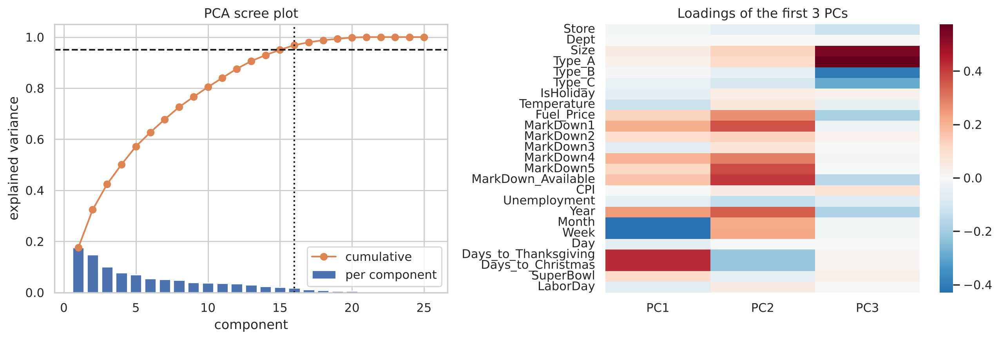

PCA              kNN=0.371  trust=0.889  silhouette=-0.016  time=0.0s


In [7]:
scaler_tr = StandardScaler().fit(X_tr)
Xs_tr, Xs_te = scaler_tr.transform(X_tr), scaler_tr.transform(X_te)

pca_full = PCA(random_state=RS).fit(Xs_tr)
cum = np.cumsum(pca_full.explained_variance_ratio_)
k95 = int(np.searchsorted(cum, 0.95) + 1)
print(f"Components for 95% variance: {k95} of {len(FEATURES)}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].bar(range(1, len(cum) + 1), pca_full.explained_variance_ratio_, color="#4C72B0", label="per component")
ax[0].plot(range(1, len(cum) + 1), cum, "o-", color="#DD8452", label="cumulative")
ax[0].axhline(.95, ls="--", c="k"); ax[0].axvline(k95, ls=":", c="k")
ax[0].set(title="PCA scree plot", xlabel="component", ylabel="explained variance"); ax[0].legend()
load = pd.DataFrame(pca_full.components_[:3].T, index=FEATURES, columns=["PC1", "PC2", "PC3"])
sns.heatmap(load, cmap="RdBu_r", center=0, ax=ax[1], yticklabels=True)
ax[1].set_title("Loadings of the first 3 PCs")
savefig("04_pca_scree_loadings")

t = time.time(); Z = PCA(2, random_state=RS).fit_transform(Xs_viz); embed_eval("PCA", Z, secs=time.time() - t)
RESULTS["pca"] = {"k95": k95, "evr": pca_full.explained_variance_ratio_.round(4).tolist(),
                  "top_pc1": load["PC1"].abs().sort_values(ascending=False).head(5).round(3).to_dict(),
                  "top_pc2": load["PC2"].abs().sort_values(ascending=False).head(5).round(3).to_dict()}

LDA              kNN=0.463  trust=0.699  silhouette=-0.020  time=0.1s
LDA explained variance ratio: [0.843 0.157]
LDA used directly as a classifier — test accuracy: 0.441


SVD              kNN=0.371  trust=0.889  silhouette=-0.016  time=0.0s


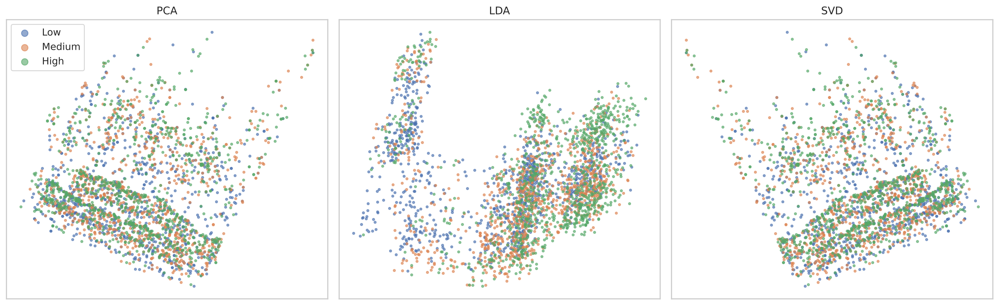

In [8]:
# LDA (supervised): at most n_classes-1 = 2 components
t = time.time()
lda = LinearDiscriminantAnalysis(n_components=2).fit(Xs_tr, y_tr)
Z = lda.transform(Xs_viz); embed_eval("LDA", Z, secs=time.time() - t)
print("LDA explained variance ratio:", lda.explained_variance_ratio_.round(3))
lda_acc = accuracy_score(y_te, lda.predict(Xs_te))
print(f"LDA used directly as a classifier — test accuracy: {lda_acc:.3f}")
RESULTS["lda"] = {"evr": lda.explained_variance_ratio_.round(4).tolist(), "clf_test_acc": round(lda_acc, 4)}

# SVD (truncated, on standardized data)
t = time.time()
svd = TruncatedSVD(n_components=2, random_state=RS).fit(Xs_viz)
Z = svd.transform(Xs_viz); embed_eval("SVD", Z, secs=time.time() - t)
svd_full = TruncatedSVD(n_components=len(FEATURES) - 1, random_state=RS).fit(Xs_tr)
RESULTS["svd"] = {"singular_values_top5": svd_full.singular_values_[:5].round(2).tolist(),
                  "evr_2": svd.explained_variance_ratio_.round(4).tolist()}

fig, ax = plt.subplots(1, 3, figsize=(16, 5))
for a, n in zip(ax, ["PCA", "LDA", "SVD"]): scatter2d(EMB[n], n, a)
ax[0].legend(markerscale=3); savefig("05_linear_embeddings")

## 5. Non-Linear Feature Reduction

Kernel PCA, SNE (implemented from scratch — scikit-learn only has t-SNE), t-SNE, UMAP, metric & non-metric MDS, Isomap and LLE.
MDS and SNE use the first 1,000 / 1,500 points of the sample because of their O(n²)–O(n³) cost.

In [9]:
# Kernel PCA (RBF) — small gamma search by kNN accuracy
best = None
for g in [0.005, 0.02, 0.05, 0.1]:
    t = time.time()
    Zg = KernelPCA(2, kernel="rbf", gamma=g, eigen_solver="dense").fit_transform(Xs_viz)
    if not np.isfinite(Zg).all():
        print(f"  gamma={g:<6} skipped (numerically unstable eigenvectors)"); continue
    acc = cross_val_score(KNeighborsClassifier(5), Zg, y_viz, cv=5).mean()
    print(f"  gamma={g:<6} kNN={acc:.3f}")
    if best is None or acc > best[0]: best = (acc, g, Zg, time.time() - t)
embed_eval("Kernel PCA", best[2], secs=best[3]); RESULTS["kpca_gamma"] = best[1]

  gamma=0.005  kNN=0.364


  gamma=0.02   kNN=0.360


  gamma=0.05   kNN=0.363


  gamma=0.1    kNN=0.361


Kernel PCA       kNN=0.364  trust=0.889  silhouette=-0.014  time=2.1s


In [10]:
def sne(X, n_components=2, perplexity=30.0, n_iter=600, lr=0.1, seed=RS):
    '''Original (asymmetric) Stochastic Neighbor Embedding — Hinton & Roweis (2002).
    Gaussian neighbourhoods in both spaces; gradient descent with momentum.'''
    rng = np.random.RandomState(seed)
    n = X.shape[0]
    D = np.square(X[:, None, :] - X[None, :, :]).sum(-1)
    P = np.zeros((n, n)); logU = np.log(perplexity)
    for i in range(n):                       # binary search on precision beta_i
        lo, hi, beta = 0.0, np.inf, 1.0
        Di = np.delete(D[i], i)
        for _ in range(60):
            p = np.exp(-Di * beta); sp = p.sum() + 1e-12
            H = np.log(sp) + beta * (Di * p).sum() / sp
            if abs(H - logU) < 1e-5: break
            if H > logU: lo = beta; beta = beta * 2 if hi == np.inf else (beta + hi) / 2
            else:        hi = beta; beta = (beta + lo) / 2
        P[i, np.arange(n) != i] = p / sp
    Y = rng.normal(0, 1e-2, (n, n_components)); vel = np.zeros_like(Y)
    for it in range(n_iter):
        DY = np.square(Y[:, None, :] - Y[None, :, :]).sum(-1)
        Q = np.exp(-DY); np.fill_diagonal(Q, 0); Q /= Q.sum(1, keepdims=True) + 1e-12
        M = (P - Q) + (P - Q).T
        grad = 2 * (M.sum(1, keepdims=True) * Y - M @ Y)          # = 2·Σ_j M_ij (y_i − y_j)
        grad = np.clip(grad, -10, 10)                              # guards against hub points
        mom = 0.5 if it < 250 else 0.8
        vel = mom * vel - lr * grad; Y += vel
    kl = np.sum(P[P > 0] * np.log(P[P > 0] / np.maximum(Q[P > 0], 1e-12)))
    return Y, kl

t = time.time(); Z, kl = sne(Xs_viz[:1500]); print(f"SNE final KL = {kl:.2f}")
embed_eval("SNE", Z, y=y_viz[:1500], secs=time.time() - t)

SNE final KL = 2387.14
SNE              kNN=0.373  trust=0.958  silhouette=-0.019  time=44.8s


In [11]:
t = time.time(); Z = TSNE(2, perplexity=30, init="pca", random_state=RS).fit_transform(Xs_viz)
embed_eval("t-SNE", Z, secs=time.time() - t)

t = time.time(); Z = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=RS).fit_transform(Xs_viz)
embed_eval("UMAP", Z, secs=time.time() - t)

n_mds = 1000
t = time.time(); Z = make_mds(metric=True, max_iter=300, n_init=1).fit_transform(Xs_viz[:n_mds])
embed_eval("Metric MDS", Z, y=y_viz[:n_mds], secs=time.time() - t)
t = time.time(); Z = make_mds(metric=False, max_iter=300, n_init=1).fit_transform(Xs_viz[:n_mds])
embed_eval("Non-metric MDS", Z, y=y_viz[:n_mds], secs=time.time() - t)

t = time.time(); Z = Isomap(n_neighbors=10, n_components=2).fit_transform(Xs_viz)
embed_eval("Isomap", Z, secs=time.time() - t)

t = time.time(); Z = LocallyLinearEmbedding(n_neighbors=12, n_components=2, method="standard",
                                             eigen_solver="dense", random_state=RS).fit_transform(Xs_viz)
embed_eval("LLE", Z, secs=time.time() - t)

t-SNE            kNN=0.395  trust=0.996  silhouette=-0.024  time=7.9s


UMAP             kNN=0.388  trust=0.990  silhouette=-0.030  time=10.8s


Metric MDS       kNN=0.374  trust=0.899  silhouette=-0.023  time=4.0s


Non-metric MDS   kNN=0.370  trust=0.900  silhouette=-0.029  time=55.2s


Isomap           kNN=0.374  trust=0.910  silhouette=-0.043  time=1.9s


LLE              kNN=0.351  trust=0.841  silhouette=-0.079  time=2.3s


,kNN acc (5-fold),Trustworthiness,Silhouette (true classes),Time (s),n
Method,,,,,
LDA,0.463,0.699,-0.020,0.143,3000
t-SNE,0.395,0.996,-0.024,7.926,3000
UMAP,0.388,0.990,-0.030,10.838,3000
Isomap,0.374,0.910,-0.043,1.889,3000
Metric MDS,0.374,0.899,-0.023,4.018,1000
SNE,0.373,0.958,-0.019,44.849,1500
PCA,0.371,0.889,-0.016,0.002,3000
SVD,0.371,0.889,-0.016,0.005,3000
Non-metric MDS,0.370,0.900,-0.029,55.155,1000


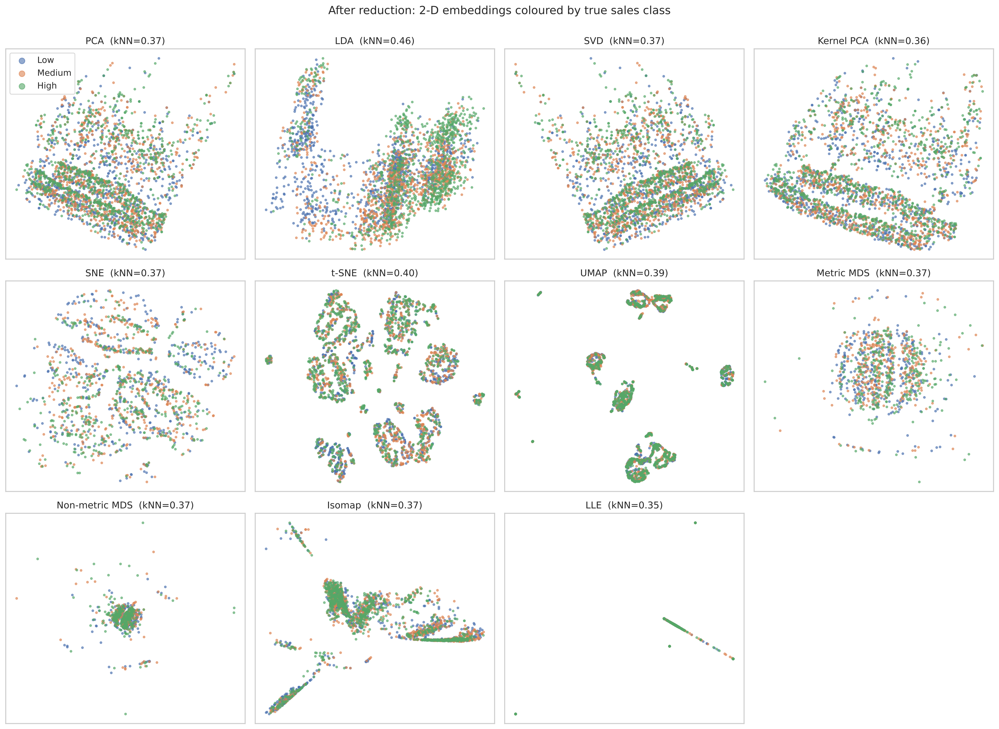

In [12]:
emb_tbl = pd.DataFrame(EMB_STATS).set_index("Method").round(3)
display(emb_tbl.sort_values("kNN acc (5-fold)", ascending=False))
RESULTS["embeddings"] = emb_tbl.reset_index().to_dict(orient="records")

names = list(EMB)
fig, ax = plt.subplots(3, 4, figsize=(18, 13))
for a, n in zip(ax.flat, names):
    scatter2d(EMB[n], f"{n}  (kNN={emb_tbl.loc[n, 'kNN acc (5-fold)']:.2f})", a,
              labels=y_viz_lbl[:len(EMB[n])])
for a in ax.flat[len(names):]: a.axis("off")
ax.flat[0].legend(markerscale=3); plt.suptitle("After reduction: 2-D embeddings coloured by true sales class", y=1.0)
savefig("06_all_embeddings")

**What do the t-SNE / UMAP islands encode?** If the compact islands were sales segments, a 5-NN classifier in the embedding would recover the sales class. Instead it recovers store type, year and promotion era almost perfectly — the islands are *store-context* groups.

In [ ]:
# What do the t-SNE / UMAP "islands" encode? 5-NN accuracy for store context vs. the sales class
type_lbl = X_viz[["Type_A", "Type_B", "Type_C"]].values.argmax(1)
rows = []
for name in ["t-SNE", "UMAP"]:
    r = {"Embedding": name}
    for lbl, yv in [("Store type", type_lbl), ("Year", X_viz["Year"].values),
                    ("MarkDown era", X_viz["MarkDown_Available"].values), ("Sales class", y_viz)]:
        r[lbl] = cross_val_score(KNeighborsClassifier(5), EMB[name], yv, cv=5).mean()
    rows.append(r)
islands = pd.DataFrame(rows).set_index("Embedding").round(3); display(islands)
RESULTS["islands"] = islands.reset_index().to_dict(orient="records")

,Store type,Year,MarkDown era,Sales class
Embedding,,,,
t-SNE,0.994,0.978,0.995,0.395
UMAP,0.988,0.963,0.993,0.388


## 6. Clustering Before and After Reduction

K-Means (k = 3) on the original 25 standardized features versus on reduced spaces.
**ARI / NMI** compare clusters to the true sales classes; **silhouette** measures cluster separation in the space used.

,Silhouette,ARI vs class,NMI vs class
Space,,,
Original (25-D),0.131,0.000,0.001
"PCA (16-D, 95% var)",0.136,0.000,0.001
PCA (2-D),0.437,0.001,0.001
LDA (2-D),0.453,0.018,0.024
t-SNE (2-D),0.473,0.008,0.008
UMAP (2-D),0.570,0.009,0.009


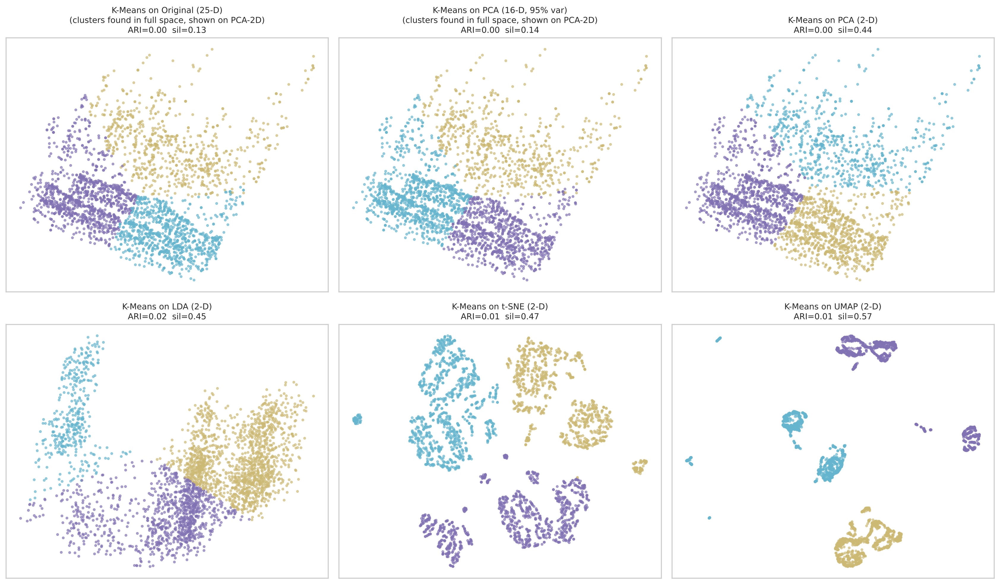

In [13]:
spaces = {"Original (25-D)": Xs_viz,
          f"PCA ({k95}-D, 95% var)": PCA(k95, random_state=RS).fit_transform(Xs_viz),
          "PCA (2-D)": EMB["PCA"], "LDA (2-D)": EMB["LDA"], "t-SNE (2-D)": EMB["t-SNE"], "UMAP (2-D)": EMB["UMAP"]}
CLU, rows = {}, []
for name, S in spaces.items():
    km = KMeans(3, n_init=10, random_state=RS).fit(S); CLU[name] = km.labels_
    rows.append({"Space": name, "Silhouette": silhouette_score(S, km.labels_),
                 "ARI vs class": adjusted_rand_score(y_viz, km.labels_),
                 "NMI vs class": normalized_mutual_info_score(y_viz, km.labels_)})
clu_tbl = pd.DataFrame(rows).set_index("Space").round(3); display(clu_tbl)
RESULTS["clustering"] = clu_tbl.reset_index().to_dict(orient="records")

fig, ax = plt.subplots(2, 3, figsize=(17, 10))
cl_cols = np.array(["#8172B3", "#CCB974", "#64B5CD"])
for a, name in zip(ax.flat, spaces):
    S = spaces[name] if spaces[name].shape[1] == 2 else EMB["PCA"]
    a.scatter(S[:, 0], S[:, 1], s=6, c=cl_cols[CLU[name]], alpha=.6)
    shown = "" if spaces[name].shape[1] == 2 else "\n(clusters found in full space, shown on PCA-2D)"
    a.set_title(f"K-Means on {name}{shown}\nARI={clu_tbl.loc[name,'ARI vs class']:.2f}  sil={clu_tbl.loc[name,'Silhouette']:.2f}", fontsize=10)
    a.set_xticks([]); a.set_yticks([])
savefig("07_clustering_before_after")

## 7. Feature Selection

All selectors use a **20,000-row subsample of the training split** (`X_fs`).
Wrapper and metaheuristic methods score a candidate subset with a fast LightGBM (60 trees) and **3-fold macro-F1**.

In [14]:
fs_idx = np.random.RandomState(RS).choice(len(X_tr), 20_000, replace=False)
X_fs, y_fs = X_tr.iloc[fs_idx].reset_index(drop=True), y_tr[fs_idx]
SUBSETS = {"All features": FEATURES}
K_SEL = 10                                     # target size for ranked/greedy methods

def fast_lgb():
    return lgb.LGBMClassifier(n_estimators=60, learning_rate=0.15, num_leaves=31,
                              random_state=RS, verbose=-1, n_jobs=-1)

### 7.1 Filter methods — variance, Spearman correlation, ANOVA F, χ², mutual information

,Variance (min-max),|Spearman|,ANOVA F,Chi2,Mutual info,Mean rank
Size,0.1084,0.2699,900.7760,325.3343,0.0614,2.00
Type_A,0.2498,0.1905,376.5996,354.0184,0.0183,3.00
Type_C,0.0908,0.1483,317.3585,553.1084,0.0144,3.75
Dept,0.0964,0.0273,81.9847,35.6261,0.4175,4.75
Store,0.0851,0.0770,79.8585,27.9670,0.0630,4.75
Type_B,0.2371,0.1038,147.2614,178.0648,0.0074,6.50
MarkDown1,0.0212,0.0272,38.8349,24.5111,0.0150,7.50
MarkDown4,0.0120,0.0495,27.5508,18.9793,0.0112,8.25
MarkDown5,0.0185,0.0254,27.3005,14.9784,0.0143,9.25
CPI,0.1494,0.0250,10.9016,7.2990,0.0116,10.50


Near-zero-variance features (<0.01): ['MarkDown3']
Filter subset: ['Size', 'Type_A', 'Type_C', 'Dept', 'Store', 'Type_B', 'MarkDown1', 'MarkDown4', 'MarkDown5', 'CPI']


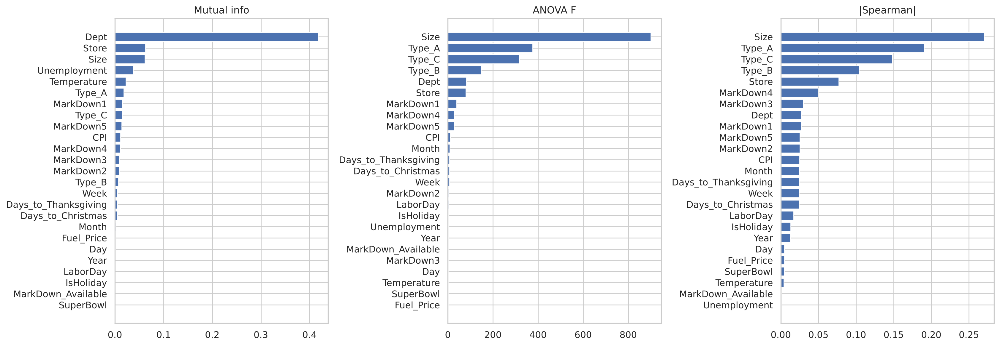

In [15]:
mm = MinMaxScaler().fit_transform(X_fs)
var = pd.Series(VarianceThreshold(0.0).fit(mm).variances_, index=FEATURES)
spear = X_fs.apply(lambda c: pd.Series(c).corr(pd.Series(y_fs), method="spearman")).abs()
F, _ = f_classif(X_fs, y_fs); C2, _ = chi2(mm, y_fs)
discrete = [X_fs[c].nunique() < 60 for c in FEATURES]
MI = mutual_info_classif(X_fs, y_fs, discrete_features=discrete, random_state=RS)

filt = pd.DataFrame({"Variance (min-max)": var, "|Spearman|": spear, "ANOVA F": F, "Chi2": C2, "Mutual info": MI},
                    index=FEATURES)
ranks = filt[["|Spearman|", "ANOVA F", "Chi2", "Mutual info"]].rank(ascending=False)
filt["Mean rank"] = ranks.mean(1)
filt = filt.sort_values("Mean rank"); display(filt.round(4))
low_var = var[var < 0.01].index.tolist()
print("Near-zero-variance features (<0.01):", low_var)
SUBSETS["Filter (rank fusion)"] = filt.index[:K_SEL].tolist()
print("Filter subset:", SUBSETS["Filter (rank fusion)"])
RESULTS["filter"] = {"table": filt.round(4).reset_index().rename(columns={"index": "Feature"}).to_dict(orient="records"),
                     "low_var": low_var}

fig, ax = plt.subplots(1, 3, figsize=(17, 6))
for a, col in zip(ax, ["Mutual info", "ANOVA F", "|Spearman|"]):
    s = filt[col].sort_values(); a.barh(s.index, s.values, color="#4C72B0"); a.set_title(col)
savefig("08_filter_scores")

### 7.2 Wrapper methods — Sequential Forward Selection, Sequential Backward Selection, RFE

In [16]:
cv3 = StratifiedKFold(3, shuffle=True, random_state=RS)
WRAP = {}
for direction in ["forward", "backward"]:
    t = time.time()
    sfs = SequentialFeatureSelector(fast_lgb(), n_features_to_select=K_SEL, direction=direction,
                                    scoring="f1_macro", cv=cv3, n_jobs=1).fit(X_fs, y_fs)
    sel = [f for f, m in zip(FEATURES, sfs.get_support()) if m]
    score = cross_val_score(fast_lgb(), X_fs[sel], y_fs, cv=cv3, scoring="f1_macro").mean()
    WRAP[f"SFS {direction}"] = {"features": sel, "cv_f1": score, "time": time.time() - t}
    SUBSETS[f"Wrapper: SFS {direction}"] = sel
    print(f"SFS {direction:<8}: F1={score:.4f}  ({time.time()-t:.0f}s)  {sel}")

t = time.time()
rfe = RFE(RandomForestClassifier(60, n_jobs=-1, random_state=RS), n_features_to_select=K_SEL, step=1).fit(X_fs, y_fs)
sel = [f for f, m in zip(FEATURES, rfe.support_) if m]
score = cross_val_score(fast_lgb(), X_fs[sel], y_fs, cv=cv3, scoring="f1_macro").mean()
WRAP["RFE (RF)"] = {"features": sel, "cv_f1": score, "time": time.time() - t}
SUBSETS["Wrapper: RFE (RF)"] = sel
print(f"RFE (RF)    : F1={score:.4f}  ({time.time()-t:.0f}s)  {sel}")
RESULTS["wrapper"] = {k: {"features": v["features"], "cv_f1": round(v["cv_f1"], 4), "time": round(v["time"], 1)}
                      for k, v in WRAP.items()}

SFS forward : F1=0.8714  (99s)  ['Store', 'Dept', 'Size', 'Type_A', 'Type_B', 'Type_C', 'IsHoliday', 'Week', 'SuperBowl', 'LaborDay']


SFS backward: F1=0.8668  (201s)  ['Store', 'Dept', 'Size', 'Type_B', 'MarkDown1', 'MarkDown2', 'MarkDown5', 'CPI', 'Unemployment', 'Week']


RFE (RF)    : F1=0.8655  (14s)  ['Store', 'Dept', 'Size', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'Week', 'Day', 'Days_to_Thanksgiving']


### 7.3 Embedded methods — L1 (Lasso), L2 (Ridge), Elastic Net logistic regression + tree importance

L1 (Lasso)           non-zero=19/25  train acc=0.441  -> 19 kept
L2 (Ridge)           non-zero=25/25  train acc=0.442  -> 10 kept


Elastic Net (α=0.5)  non-zero=21/25  train acc=0.441  -> 21 kept


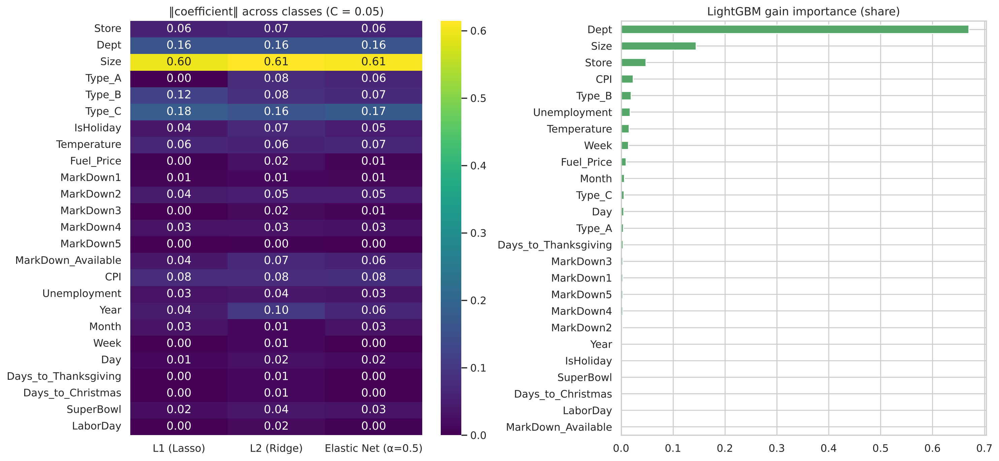

In [17]:
Xs_fs = StandardScaler().fit_transform(X_fs)
EMBD = {}
for name, l1r in [("L1 (Lasso)", 1.0), ("L2 (Ridge)", 0.0), ("Elastic Net (α=0.5)", 0.5)]:
    t = time.time()
    m = make_lr(l1_ratio=l1r, C=0.05).fit(Xs_fs, y_fs)
    coef = pd.Series(np.linalg.norm(m.coef_, axis=0), index=FEATURES)
    nz = coef[coef > 1e-6].sort_values(ascending=False)
    acc = accuracy_score(y_fs, m.predict(Xs_fs))
    sel = nz.index.tolist() if l1r > 0 else coef.sort_values(ascending=False).index[:K_SEL].tolist()
    EMBD[name] = {"coef": coef, "n_nonzero": int((coef > 1e-6).sum()), "train_acc": acc, "features": sel,
                  "time": time.time() - t}
    SUBSETS[f"Embedded: {name}"] = sel
    print(f"{name:<20} non-zero={EMBD[name]['n_nonzero']:>2}/{len(FEATURES)}  train acc={acc:.3f}  -> {len(sel)} kept")

gbm = lgb.LGBMClassifier(n_estimators=200, random_state=RS, verbose=-1, importance_type="gain").fit(X_fs, y_fs)
imp = pd.Series(gbm.feature_importances_, index=FEATURES).sort_values(ascending=False)
SUBSETS["Embedded: LightGBM gain"] = imp.index[:K_SEL].tolist()

coef_df = pd.DataFrame({k: v["coef"] for k, v in EMBD.items()})
fig, ax = plt.subplots(1, 2, figsize=(15, 7))
sns.heatmap(coef_df, annot=True, fmt=".2f", cmap="viridis", ax=ax[0], yticklabels=True)
ax[0].set_title("‖coefficient‖ across classes (C = 0.05)")
(imp / imp.sum()).sort_values().plot.barh(ax=ax[1], color="#55A868"); ax[1].set_title("LightGBM gain importance (share)")
savefig("09_embedded")
RESULTS["embedded"] = {k: {"n_nonzero": v["n_nonzero"], "train_acc": round(v["train_acc"], 4), "features": v["features"],
                           "coef": v["coef"].round(4).to_dict()} for k, v in EMBD.items()}
RESULTS["lgb_gain_share"] = (imp / imp.sum()).round(4).to_dict()

### 7.4 Metaheuristic feature selection — Genetic Algorithm, Binary PSO, Simulated Annealing

Each candidate is a bit-mask over the 25 features. **Fitness** = 3-fold macro-F1 (fast LightGBM) − λ·(selected / 25), with λ = 0.02 to reward compact subsets.

Genetic Algorithm    F1=0.8720 fitness=0.8672  6 feats  new evals=331  (193s)
   ['Store', 'Dept', 'Size', 'Type_B', 'CPI', 'Week']


Binary PSO           F1=0.8703 fitness=0.8631  9 feats  new evals=400  (242s)
   ['Store', 'Dept', 'Size', 'Type_B', 'IsHoliday', 'CPI', 'Days_to_Thanksgiving', 'SuperBowl', 'LaborDay']


Simulated Annealing  F1=0.8730 fitness=0.8690  5 feats  new evals=248  (151s)
   ['Store', 'Dept', 'Size', 'Type_B', 'Days_to_Thanksgiving']


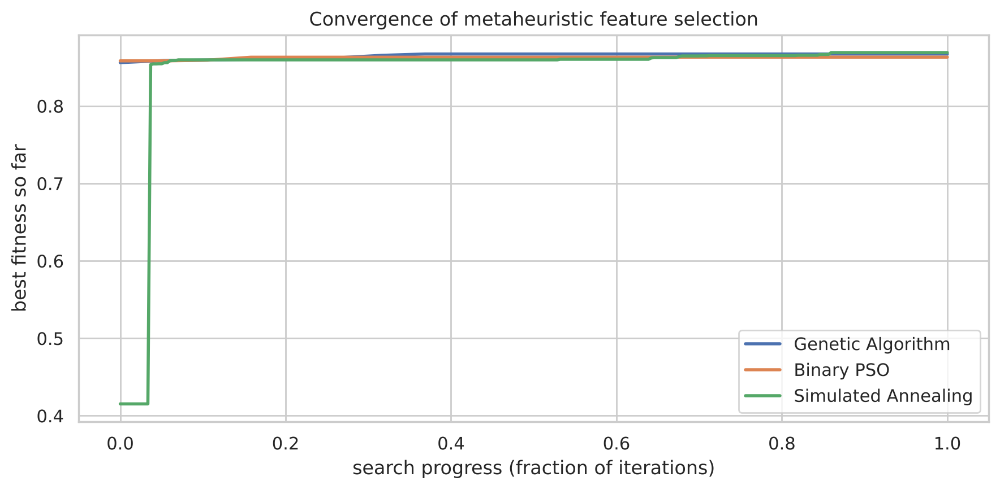

In [18]:
LAMBDA, D = 0.02, len(FEATURES)
_cache = {}
def fitness(mask):
    key = mask.tobytes()
    if key not in _cache:
        if mask.sum() == 0: _cache[key] = (0.0, 0.0)
        else:
            cols = [f for f, b in zip(FEATURES, mask) if b]
            f1 = cross_val_score(fast_lgb(), X_fs[cols], y_fs, cv=cv3, scoring="f1_macro").mean()
            _cache[key] = (f1 - LAMBDA * mask.sum() / D, f1)
    return _cache[key]

def genetic_algorithm(pop=24, gens=20, pc=0.9, pm=1 / D, elite=2, seed=RS):
    rng = np.random.RandomState(seed)
    P = (rng.rand(pop, D) < 0.5).astype(np.int8); hist = []
    for g in range(gens):
        fit = np.array([fitness(ind)[0] for ind in P])
        order = np.argsort(-fit); hist.append(fit[order[0]])
        new = [P[i].copy() for i in order[:elite]]
        while len(new) < pop:
            a, b = [P[max(rng.choice(pop, 3, replace=False), key=lambda i: fit[i])] for _ in range(2)]  # tournament
            child = np.where(rng.rand(D) < 0.5, a, b) if rng.rand() < pc else a.copy()         # uniform crossover
            flip = rng.rand(D) < pm; child[flip] = 1 - child[flip]                             # bit-flip mutation
            new.append(child.astype(np.int8))
        P = np.array(new)
    fit = np.array([fitness(ind)[0] for ind in P]); best = P[np.argmax(fit)]
    return best, hist

def binary_pso(n=20, iters=20, w=0.7, c1=1.5, c2=1.5, vmax=4, seed=RS):
    rng = np.random.RandomState(seed)
    X = (rng.rand(n, D) < 0.5).astype(np.int8); V = rng.uniform(-1, 1, (n, D))
    pb = X.copy(); pbf = np.array([fitness(x)[0] for x in X])
    gb = pb[np.argmax(pbf)].copy(); gbf = pbf.max(); hist = []
    for _ in range(iters):
        V = np.clip(w * V + c1 * rng.rand(n, D) * (pb - X) + c2 * rng.rand(n, D) * (gb - X), -vmax, vmax)
        X = (rng.rand(n, D) < 1 / (1 + np.exp(-V))).astype(np.int8)              # sigmoid transfer
        f = np.array([fitness(x)[0] for x in X])
        imp_ = f > pbf; pb[imp_], pbf[imp_] = X[imp_], f[imp_]
        if pbf.max() > gbf: gbf = pbf.max(); gb = pb[np.argmax(pbf)].copy()
        hist.append(gbf)
    return gb, hist

def simulated_annealing(iters=300, T0=0.02, alpha=0.985, seed=RS):
    rng = np.random.RandomState(seed)
    cur = (rng.rand(D) < 0.5).astype(np.int8); cf = fitness(cur)[0]
    best, bf, T, hist = cur.copy(), cf, T0, []
    for _ in range(iters):
        cand = cur.copy(); j = rng.randint(D); cand[j] = 1 - cand[j]
        f = fitness(cand)[0]
        if f > cf or rng.rand() < np.exp((f - cf) / T): cur, cf = cand, f
        if cf > bf: best, bf = cur.copy(), cf
        T *= alpha; hist.append(bf)
    return best, hist

META = {}
for name, fn in [("Genetic Algorithm", genetic_algorithm), ("Binary PSO", binary_pso), ("Simulated Annealing", simulated_annealing)]:
    n0, t = len(_cache), time.time()
    mask, hist = fn()
    sel = [f for f, b in zip(FEATURES, mask) if b]
    fit_val, f1 = fitness(mask)
    META[name] = {"features": sel, "fitness": fit_val, "cv_f1": f1, "hist": hist,
                  "evals": len(_cache) - n0, "time": time.time() - t}
    SUBSETS[f"Metaheuristic: {name}"] = sel
    print(f"{name:<20} F1={f1:.4f} fitness={fit_val:.4f}  {len(sel)} feats  new evals={len(_cache)-n0}  ({time.time()-t:.0f}s)\n   {sel}")

plt.figure(figsize=(9, 4.5))
for name, v in META.items():
    h = np.array(v["hist"]); plt.plot(np.linspace(0, 1, len(h)), h, lw=2, label=name)
plt.xlabel("search progress (fraction of iterations)"); plt.ylabel("best fitness so far")
plt.title("Convergence of metaheuristic feature selection"); plt.legend()
savefig("10_metaheuristic_convergence")
RESULTS["meta"] = {k: {kk: (round(vv, 4) if isinstance(vv, float) else vv) for kk, vv in v.items() if kk != "hist"}
                   | {"hist": [round(float(x), 4) for x in v["hist"]]} for k, v in META.items()}
RESULTS["meta_params"] = {"lambda": LAMBDA, "GA": "pop=24, gens=20, pc=0.9, pm=1/25, tournament k=3, elitism 2",
                          "BPSO": "20 particles, 20 iters, w=0.7, c1=c2=1.5, vmax=4, sigmoid transfer",
                          "SA": "300 iters, T0=0.02, alpha=0.985, single bit-flip"}

,Method,# features,Features
0,All features,25,"Store, Dept, Size, Type_A, Type_B, Type_C, IsH..."
1,Filter (rank fusion),10,"Size, Type_A, Type_C, Dept, Store, Type_B, Mar..."
2,Wrapper: SFS forward,10,"Store, Dept, Size, Type_A, Type_B, Type_C, IsH..."
3,Wrapper: SFS backward,10,"Store, Dept, Size, Type_B, MarkDown1, MarkDown..."
4,Wrapper: RFE (RF),10,"Store, Dept, Size, Temperature, Fuel_Price, CP..."
5,Embedded: L1 (Lasso),19,"Size, Type_C, Dept, Type_B, CPI, Temperature, ..."
6,Embedded: L2 (Ridge),10,"Size, Dept, Type_C, Year, Type_B, CPI, Type_A,..."
7,Embedded: Elastic Net (α=0.5),21,"Size, Type_C, Dept, CPI, Type_B, Temperature, ..."
8,Embedded: LightGBM gain,10,"Dept, Size, Store, CPI, Type_B, Unemployment, ..."
9,Metaheuristic: Genetic Algorithm,6,"Store, Dept, Size, Type_B, CPI, Week"


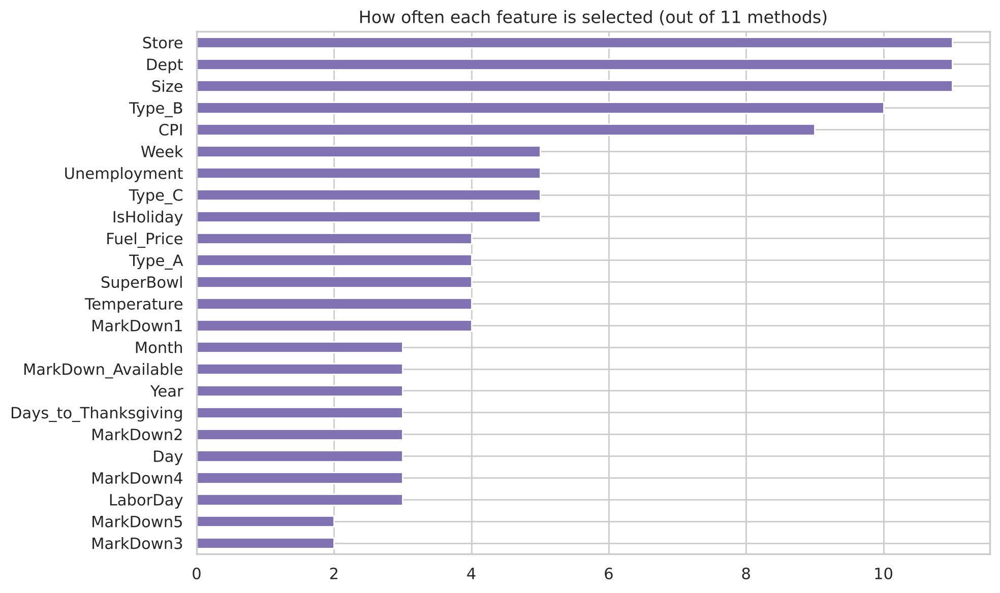

In [19]:
# Summary of all selected subsets
sel_tbl = pd.DataFrame([{"Method": k, "# features": len(v), "Features": ", ".join(v)} for k, v in SUBSETS.items()])
display(sel_tbl)
freq = pd.Series([f for k, v in SUBSETS.items() if k != "All features" for f in v]).value_counts()
plt.figure(figsize=(10, 6)); freq.sort_values().plot.barh(color="#8172B3")
plt.title(f"How often each feature is selected (out of {len(SUBSETS)-1} methods)")
savefig("11_selection_frequency")
RESULTS["subsets"] = SUBSETS; RESULTS["selection_freq"] = freq.to_dict()

### 7.5 Reduction *after* selection — does removing noisy features help the embeddings?

Section 5 showed weak class separation in 2-D. We repeat PCA, LDA, t-SNE and UMAP (plus K-Means) on the same 3,000 points but using only the **GA-selected features**.

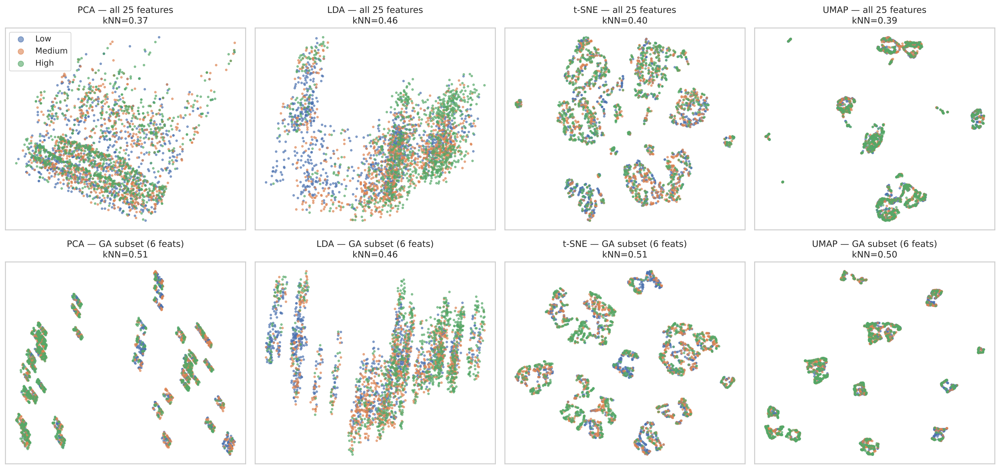

,kNN (all 25),kNN (GA 6),Silhouette (all 25),Silhouette (GA 6),Trust (GA),K-Means ARI (GA)
Method,,,,,,
PCA,0.371,0.505,-0.016,-0.031,0.938,0.017
LDA,0.463,0.461,-0.020,-0.018,0.891,0.027
t-SNE,0.395,0.515,-0.024,-0.017,0.999,0.005
UMAP,0.388,0.500,-0.030,-0.025,0.998,0.026


In [20]:
GA_FEATS = SUBSETS["Metaheuristic: Genetic Algorithm"]
Xs_viz_ga = StandardScaler().fit_transform(X_viz[GA_FEATS])
rows = []
fig, ax = plt.subplots(2, 4, figsize=(19, 9))
for j, (name, fn) in enumerate([
        ("PCA", lambda X: PCA(2, random_state=RS).fit_transform(X)),
        ("LDA", lambda X: LinearDiscriminantAnalysis(n_components=2).fit_transform(X, y_viz)),
        ("t-SNE", lambda X: TSNE(2, perplexity=30, init="pca", random_state=RS).fit_transform(X)),
        ("UMAP", lambda X: umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=RS).fit_transform(X))]):
    Zga = fn(Xs_viz_ga)
    km = KMeans(3, n_init=10, random_state=RS).fit(Zga)
    r = {"Method": name,
         "kNN (all 25)": cross_val_score(KNeighborsClassifier(5), EMB[name], y_viz, cv=5).mean(),
         f"kNN (GA {len(GA_FEATS)})": cross_val_score(KNeighborsClassifier(5), Zga, y_viz, cv=5).mean(),
         "Silhouette (all 25)": silhouette_score(EMB[name], y_viz),
         f"Silhouette (GA {len(GA_FEATS)})": silhouette_score(Zga, y_viz),
         "Trust (GA)": trustworthiness(Xs_viz_ga, Zga, n_neighbors=10),
         "K-Means ARI (GA)": adjusted_rand_score(y_viz, km.labels_)}
    rows.append(r)
    scatter2d(EMB[name], f"{name} — all 25 features\nkNN={r['kNN (all 25)']:.2f}", ax[0, j])
    scatter2d(Zga, f"{name} — GA subset ({len(GA_FEATS)} feats)\nkNN={r[f'kNN (GA {len(GA_FEATS)})']:.2f}", ax[1, j])
ax[0, 0].legend(markerscale=3)
savefig("17_reduction_after_selection")
ras = pd.DataFrame(rows).set_index("Method").round(3); display(ras)
RESULTS["reduction_after_selection"] = {"features": GA_FEATS, "table": ras.reset_index().to_dict(orient="records")}

## 8. Model Implementation

Nine classifiers on the **80% training split** (all 25 features). Scale-sensitive models are wrapped in a `StandardScaler` pipeline.

In [21]:
MODELS = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Gaussian NB":         make_pipeline(StandardScaler(), GaussianNB()),
    "KNN (k=15)":          make_pipeline(StandardScaler(), KNeighborsClassifier(15, n_jobs=-1)),
    "Decision Tree":       DecisionTreeClassifier(random_state=RS),
    "Random Forest":       RandomForestClassifier(150, min_samples_leaf=2, n_jobs=-1, random_state=RS),
    "Extra Trees":         ExtraTreesClassifier(150, min_samples_leaf=2, n_jobs=-1, random_state=RS),
    "MLP":                 make_pipeline(StandardScaler(), MLPClassifier((128, 64), early_stopping=True,
                                                                         max_iter=200, random_state=RS)),
    "XGBoost":             xgb.XGBClassifier(n_estimators=400, max_depth=8, learning_rate=0.1, subsample=0.9,
                                             colsample_bytree=0.9, tree_method="hist", random_state=RS, n_jobs=-1),
    "LightGBM":            lgb.LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=127,
                                              random_state=RS, verbose=-1, n_jobs=-1),
}

def evaluate(model, Xa, ya, Xb, yb):
    t = time.time(); model.fit(Xa, ya); fit_t = time.time() - t
    pa, pb, proba = model.predict(Xa), model.predict(Xb), model.predict_proba(Xb)
    acc = accuracy_score(yb, pb)
    return {"Train acc": accuracy_score(ya, pa), "Test acc": acc, "Error rate": 1 - acc,
            "Precision": precision_score(yb, pb, average="macro"), "Recall": recall_score(yb, pb, average="macro"),
            "F1": f1_score(yb, pb, average="macro"), "ROC-AUC": roc_auc_score(yb, proba, multi_class="ovr"),
            "Fit time (s)": fit_t}, pb, proba

HOLD, PRED, PROBA = {}, {}, {}
for name, m in MODELS.items():
    HOLD[name], PRED[name], PROBA[name] = evaluate(m, X_tr, y_tr, X_te, y_te)
    MODELS[name] = clone(m); gc.collect()          # keep only the un-fitted spec (saves several GB for forests)
    print(f"{name:<20} test acc={HOLD[name]['Test acc']:.4f}  F1={HOLD[name]['F1']:.4f}  ({HOLD[name]['Fit time (s)']:.1f}s)")

Logistic Regression  test acc=0.4439  F1=0.4434  (0.2s)


Gaussian NB          test acc=0.4617  F1=0.4601  (0.1s)


KNN (k=15)           test acc=0.5081  F1=0.5055  (0.0s)


Decision Tree        test acc=0.9019  F1=0.9018  (0.6s)


Random Forest        test acc=0.6707  F1=0.6701  (7.4s)


Extra Trees          test acc=0.6008  F1=0.5989  (4.9s)


MLP                  test acc=0.6898  F1=0.6870  (61.7s)


XGBoost              test acc=0.9318  F1=0.9318  (7.7s)


LightGBM             test acc=0.9344  F1=0.9344  (9.2s)


## 9. Model Evaluation

### 9.1 Hold-out (80% train / 20% test) — all metrics
Precision, recall and F1 are **macro-averaged** over the three classes; ROC-AUC is **one-vs-rest macro**.
A train–test accuracy gap above 5 points is flagged as **over-fitting**; a test accuracy below 70% with a small gap as **under-fitting**.

In [22]:
hold = pd.DataFrame(HOLD).T
hold["Gap (train-test)"] = hold["Train acc"] - hold["Test acc"]
hold["Diagnosis"] = np.where(hold["Gap (train-test)"] > 0.05, "Over-fitting",
                    np.where(hold["Test acc"] < 0.70, "Under-fitting", "Good fit"))
hold = hold.sort_values("F1", ascending=False)
display(hold.style.format({c: "{:.4f}" for c in hold.columns if c not in ("Diagnosis", "Fit time (s)")} | {"Fit time (s)": "{:.1f}"})
        .background_gradient(subset=["Test acc", "F1", "ROC-AUC"], cmap="Greens"))
BEST = hold.index[0]; print("Best model on hold-out F1:", BEST)
RESULTS["holdout"] = hold.round(4).reset_index().rename(columns={"index": "Model"}).to_dict(orient="records")
RESULTS["best_model"] = BEST

,Train acc,Test acc,Error rate,Precision,Recall,F1,ROC-AUC,Fit time (s),Gap (train-test),Diagnosis
LightGBM,0.9929,0.9344,0.0656,0.9344,0.9344,0.9344,0.9906,9.2,0.0585,Over-fitting
XGBoost,0.9873,0.9318,0.0682,0.9319,0.9319,0.9318,0.9899,7.7,0.0555,Over-fitting
Decision Tree,1.0000,0.9019,0.0981,0.9018,0.9019,0.9018,0.9264,0.6,0.0981,Over-fitting
MLP,0.7260,0.6898,0.3102,0.6870,0.6898,0.6870,0.8524,61.7,0.0362,Under-fitting
Random Forest,0.9246,0.6707,0.3293,0.6706,0.6708,0.6701,0.8496,7.4,0.2539,Over-fitting
Extra Trees,0.9103,0.6008,0.3992,0.5981,0.6009,0.5989,0.7883,4.9,0.3094,Over-fitting
KNN (k=15),0.5916,0.5081,0.4919,0.5065,0.5081,0.5055,0.6939,0.0,0.0836,Over-fitting
Gaussian NB,0.4560,0.4617,0.5383,0.4609,0.4617,0.4601,0.6380,0.1,-0.0057,Under-fitting
Logistic Regression,0.4412,0.4439,0.5561,0.4509,0.4439,0.4434,0.6309,0.2,-0.0027,Under-fitting


Best model on hold-out F1: LightGBM


### 9.2 Stratified 5-fold cross-validation (on the full 100k modelling sample)

Logistic Regression  acc = 0.4410 ± 0.0007   (1s)


Gaussian NB          acc = 0.4570 ± 0.0034   (0s)


KNN (k=15)           acc = 0.5091 ± 0.0029   (24s)


Decision Tree        acc = 0.9042 ± 0.0014   (3s)


Random Forest        acc = 0.6699 ± 0.0019   (41s)


Extra Trees          acc = 0.5953 ± 0.0050   (30s)


MLP                  acc = 0.6645 ± 0.0235   (185s)


XGBoost              acc = 0.9306 ± 0.0013   (40s)


LightGBM             acc = 0.9342 ± 0.0020   (75s)


,Acc mean,Acc std,F1 mean,F1 std,AUC mean,fold accs
LightGBM,0.93422,0.002045,0.934289,0.002015,0.990639,"[0.9312, 0.9336, 0.9376, 0.9338, 0.9349]"
XGBoost,0.93064,0.001312,0.930719,0.001274,0.98983,"[0.9296, 0.9294, 0.9324, 0.9298, 0.932]"
Decision Tree,0.90422,0.001391,0.904232,0.001316,0.928165,"[0.9019, 0.906, 0.9039, 0.904, 0.9053]"
Random Forest,0.66992,0.001931,0.669495,0.001829,0.849244,"[0.6724, 0.6704, 0.6666, 0.6692, 0.671]"
MLP,0.66451,0.023518,0.660635,0.022824,0.836051,"[0.6892, 0.6562, 0.694, 0.6508, 0.6324]"
Extra Trees,0.59528,0.005035,0.593555,0.004947,0.785542,"[0.5966, 0.59, 0.5919, 0.5935, 0.6044]"
KNN (k=15),0.50907,0.002912,0.506954,0.002943,0.691542,"[0.5077, 0.5046, 0.5133, 0.509, 0.5107]"
Gaussian NB,0.45695,0.003352,0.454812,0.005434,0.634701,"[0.46, 0.4608, 0.4554, 0.457, 0.4515]"
Logistic Regression,0.441,0.000699,0.440266,0.00058,0.629447,"[0.4408, 0.4398, 0.4418, 0.441, 0.4417]"


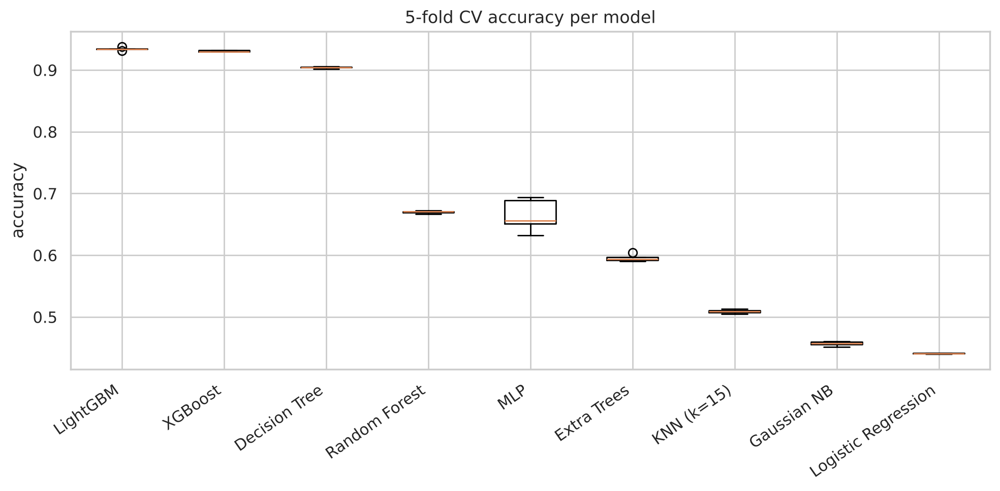

In [23]:
cv5 = StratifiedKFold(5, shuffle=True, random_state=RS)
CV = {}
for name, m in MODELS.items():
    t = time.time()
    r = cross_validate(m, X_all, y_all, cv=cv5, scoring=["accuracy", "f1_macro", "roc_auc_ovr"], n_jobs=1)
    CV[name] = {"Acc mean": r["test_accuracy"].mean(), "Acc std": r["test_accuracy"].std(),
                "F1 mean": r["test_f1_macro"].mean(), "F1 std": r["test_f1_macro"].std(),
                "AUC mean": r["test_roc_auc_ovr"].mean(), "fold accs": r["test_accuracy"].round(4).tolist()}
    print(f"{name:<20} acc = {CV[name]['Acc mean']:.4f} ± {CV[name]['Acc std']:.4f}   ({time.time()-t:.0f}s)")
cv_tbl = pd.DataFrame(CV).T.sort_values("Acc mean", ascending=False); display(cv_tbl)
RESULTS["cv"] = {k: {kk: (round(vv, 4) if isinstance(vv, float) else vv) for kk, vv in v.items()} for k, v in CV.items()}

plt.figure(figsize=(10, 5))
order = cv_tbl.index
plt.boxplot([CV[n]["fold accs"] for n in order])
plt.xticks(range(1, len(order) + 1), order, rotation=35, ha="right"); plt.ylabel("accuracy"); plt.title("5-fold CV accuracy per model")
savefig("12_cv_boxplot")

### 9.3 Confusion matrices and their interpretation

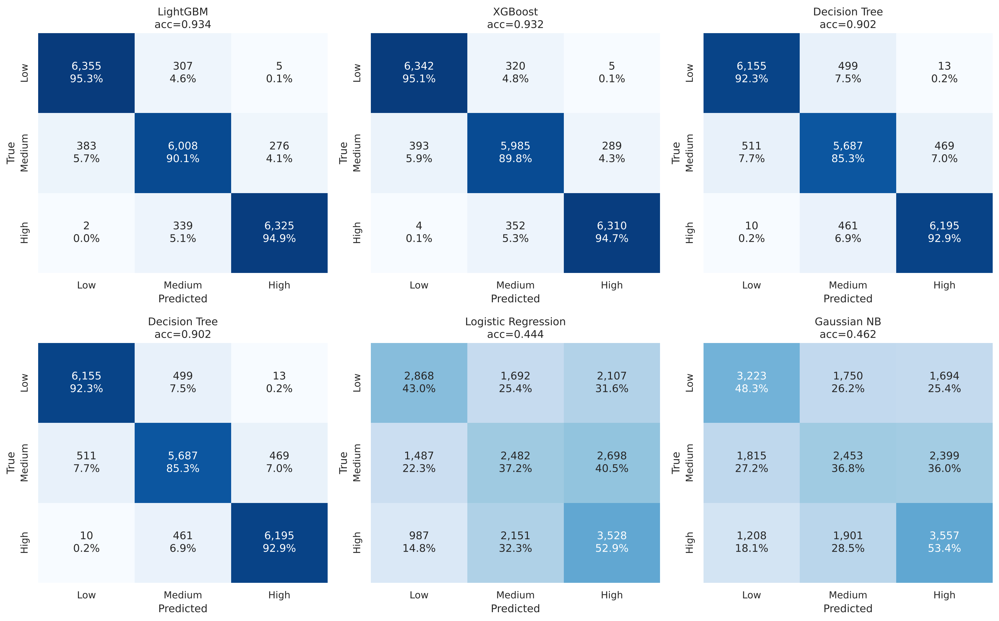


LightGBM:
   Low    recall=0.953  precision=0.943
   Medium recall=0.901  precision=0.903
   High   recall=0.949  precision=0.957
   Most frequent confusion: true Medium → predicted Low (383 cases, 29.2% of all errors)
   'Far' errors Low↔High: 7 (0.5% of errors) — the rest are between neighbouring levels

XGBoost:
   Low    recall=0.951  precision=0.941
   Medium recall=0.898  precision=0.899
   High   recall=0.947  precision=0.955
   Most frequent confusion: true Medium → predicted Low (393 cases, 28.8% of all errors)
   'Far' errors Low↔High: 9 (0.7% of errors) — the rest are between neighbouring levels

Decision Tree:
   Low    recall=0.923  precision=0.922
   Medium recall=0.853  precision=0.856
   High   recall=0.929  precision=0.928
   Most frequent confusion: true Medium → predicted Low (511 cases, 26.0% of all errors)
   'Far' errors Low↔High: 23 (1.2% of errors) — the rest are between neighbouring levels

Decision Tree:
   Low    recall=0.923  precision=0.922
   Medium recal

In [24]:
show = list(hold.index[:3]) + ["Decision Tree", "Logistic Regression", "Gaussian NB"]
fig, ax = plt.subplots(2, 3, figsize=(16, 10))
CM = {}
for a, name in zip(ax.flat, show):
    cm = confusion_matrix(y_te, PRED[name]); CM[name] = cm.tolist()
    cmn = cm / cm.sum(1, keepdims=True)
    annot = np.array([[f"{cm[i,j]:,}\n{cmn[i,j]:.1%}" for j in range(3)] for i in range(3)])
    sns.heatmap(cmn, annot=annot, fmt="", cmap="Blues", cbar=False, ax=a,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, vmin=0, vmax=1)
    a.set(title=f"{name}\nacc={HOLD[name]['Test acc']:.3f}", xlabel="Predicted", ylabel="True")
savefig("13_confusion_matrices")
RESULTS["cm"] = CM

def interpret_cm(name):
    cm = np.array(CM[name]); rec = cm.diagonal() / cm.sum(1); prec = cm.diagonal() / cm.sum(0)
    off = cm.copy(); np.fill_diagonal(off, 0); i, j = np.unravel_index(off.argmax(), off.shape)
    far = cm[0, 2] + cm[2, 0]
    print(f"\n{name}:")
    for k, c in enumerate(CLASS_NAMES): print(f"   {c:<6} recall={rec[k]:.3f}  precision={prec[k]:.3f}")
    print(f"   Most frequent confusion: true {CLASS_NAMES[i]} → predicted {CLASS_NAMES[j]} ({off[i,j]:,} cases, "
          f"{off[i,j]/off.sum():.1%} of all errors)")
    print(f"   'Far' errors Low↔High: {far:,} ({far/off.sum():.1%} of errors) — the rest are between neighbouring levels")
    return {"recall": rec.round(4).tolist(), "precision": prec.round(4).tolist(),
            "top_confusion": [CLASS_NAMES[i], CLASS_NAMES[j], int(off[i, j])], "far_errors": int(far),
            "far_share": round(far / off.sum(), 4), "n_errors": int(off.sum())}
RESULTS["cm_interp"] = {n: interpret_cm(n) for n in show}

### 9.4 ROC curves and AUC

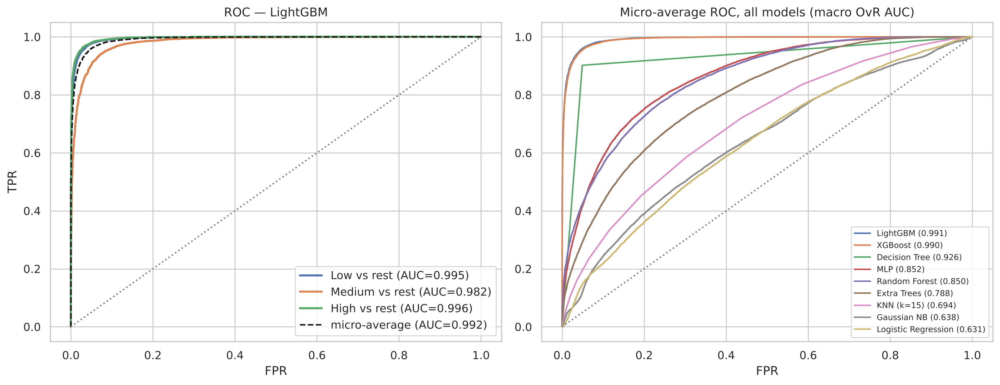

In [25]:
yb = label_binarize(y_te, classes=[0, 1, 2])
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for k, c in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(yb[:, k], PROBA[BEST][:, k])
    ax[0].plot(fpr, tpr, lw=2, color=PALETTE[c], label=f"{c} vs rest (AUC={auc(fpr, tpr):.3f})")
fpr, tpr, _ = roc_curve(yb.ravel(), PROBA[BEST].ravel())
ax[0].plot(fpr, tpr, "k--", lw=1.5, label=f"micro-average (AUC={auc(fpr, tpr):.3f})")
ax[0].plot([0, 1], [0, 1], ":", c="grey"); ax[0].set(title=f"ROC — {BEST}", xlabel="FPR", ylabel="TPR"); ax[0].legend()
for name in hold.index:
    fpr, tpr, _ = roc_curve(yb.ravel(), PROBA[name].ravel())
    ax[1].plot(fpr, tpr, lw=1.5, label=f"{name} ({HOLD[name]['ROC-AUC']:.3f})")
ax[1].plot([0, 1], [0, 1], ":", c="grey"); ax[1].set(title="Micro-average ROC, all models (macro OvR AUC)", xlabel="FPR")
ax[1].legend(fontsize=8)
savefig("14_roc_curves")
RESULTS["roc_per_class_best"] = [round(roc_auc_score(yb[:, k], PROBA[BEST][:, k]), 4) for k in range(3)]

### 9.5 Over-fitting / under-fitting analysis — learning and validation curves

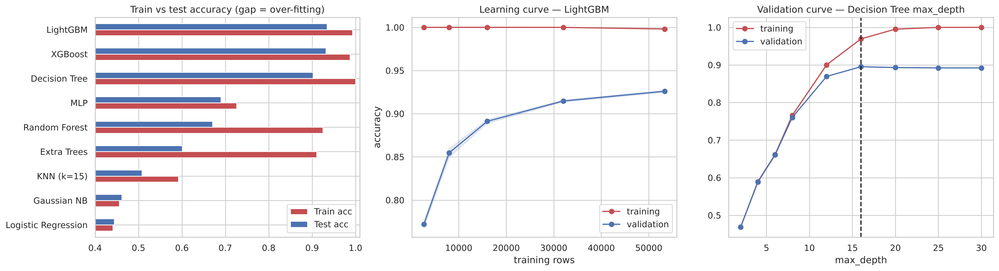

In [26]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
gap = hold[["Train acc", "Test acc"]].sort_values("Test acc")
gap.plot.barh(ax=ax[0], color=["#C44E52", "#4C72B0"]); ax[0].set_xlim(0.4, 1.01)
ax[0].set_title("Train vs test accuracy (gap = over-fitting)")

sizes, tr_s, va_s = learning_curve(MODELS[BEST], X_tr, y_tr, cv=StratifiedKFold(3, shuffle=True, random_state=RS),
                                   train_sizes=[0.05, 0.15, 0.3, 0.6, 1.0], scoring="accuracy", n_jobs=1)
for s, lab, col in [(tr_s, "training", "#C44E52"), (va_s, "validation", "#4C72B0")]:
    ax[1].plot(sizes, s.mean(1), "o-", color=col, label=lab)
    ax[1].fill_between(sizes, s.mean(1) - s.std(1), s.mean(1) + s.std(1), color=col, alpha=.15)
ax[1].set(title=f"Learning curve — {BEST}", xlabel="training rows", ylabel="accuracy"); ax[1].legend()

depths = [2, 4, 6, 8, 12, 16, 20, 25, 30]
tr_d, va_d = validation_curve(DecisionTreeClassifier(random_state=RS), X_tr, y_tr, param_name="max_depth",
                              param_range=depths, cv=StratifiedKFold(3, shuffle=True, random_state=RS), scoring="accuracy")
ax[2].plot(depths, tr_d.mean(1), "o-", color="#C44E52", label="training")
ax[2].plot(depths, va_d.mean(1), "o-", color="#4C72B0", label="validation")
best_d = depths[int(np.argmax(va_d.mean(1)))]
ax[2].axvline(best_d, ls="--", c="k"); ax[2].set(title="Validation curve — Decision Tree max_depth", xlabel="max_depth")
ax[2].legend(); savefig("15_over_under_fitting")
RESULTS["learning_curve"] = {"sizes": sizes.tolist(), "train": tr_s.mean(1).round(4).tolist(), "val": va_s.mean(1).round(4).tolist()}
RESULTS["val_curve_dt"] = {"depths": depths, "train": tr_d.mean(1).round(4).tolist(), "val": va_d.mean(1).round(4).tolist(),
                           "best_depth": best_d}

### 9.5b Why do Random Forest and Extra Trees under-perform a single tree?

`Dept` alone carries about two-thirds of LightGBM's gain. With the default `max_features="sqrt"` (5 of 25 candidates per split), `Dept` is only available at ~20% of splits, so the forests build most splits on store-week context variables that are noise at the department level.
We test this by varying `max_features`.

In [27]:
abl = []
for name, cls in [("Random Forest", RandomForestClassifier), ("Extra Trees", ExtraTreesClassifier)]:
    for mf in ["sqrt", 0.5, 1.0]:
        m = cls(150, min_samples_leaf=2, max_features=mf, n_jobs=-1, random_state=RS)
        r, _, _ = evaluate(m, X_tr, y_tr, X_te, y_te)
        abl.append({"Model": name, "max_features": str(mf), "Train acc": r["Train acc"], "Test acc": r["Test acc"],
                    "F1": r["F1"], "ROC-AUC": r["ROC-AUC"]})
        del m; gc.collect()
abl_tbl = pd.DataFrame(abl); display(abl_tbl.round(4))
RESULTS["forest_ablation"] = abl_tbl.round(4).to_dict(orient="records")

,Model,max_features,Train acc,Test acc,F1,ROC-AUC
0,Random Forest,sqrt,0.9246,0.6708,0.6701,0.8496
1,Random Forest,0.5,0.9897,0.9138,0.9137,0.9813
2,Random Forest,1.0,0.9888,0.9301,0.9300,0.9881
3,Extra Trees,sqrt,0.9102,0.6008,0.5989,0.7883
4,Extra Trees,0.5,0.9975,0.9054,0.9051,0.9769
5,Extra Trees,1.0,0.9965,0.9327,0.9327,0.9896


### 9.6 Effect of feature reduction / selection on the best model

The best model is retrained on the 80% split using each feature subset (and on PCA / SVD / LDA projections) and tested on the same 20%.

,# dims,Train acc,Test acc,Error rate,Precision,Recall,F1,ROC-AUC,Fit time (s)
Input,,,,,,,,,
Metaheuristic: Genetic Algorithm,6,0.9823,0.9370,0.0631,0.9369,0.9370,0.9369,0.9915,5.4932
Metaheuristic: Binary PSO,9,0.9826,0.9364,0.0636,0.9364,0.9365,0.9364,0.9915,5.7441
Wrapper: RFE (RF),10,0.9922,0.9354,0.0646,0.9354,0.9354,0.9354,0.9910,6.2318
Embedded: LightGBM gain,10,0.9907,0.9346,0.0654,0.9346,0.9346,0.9346,0.9911,6.5622
All features,25,0.9929,0.9344,0.0656,0.9344,0.9344,0.9344,0.9906,9.4780
Wrapper: SFS backward,10,0.9864,0.9342,0.0657,0.9342,0.9343,0.9342,0.9909,7.2466
Wrapper: SFS forward,10,0.9695,0.9332,0.0667,0.9332,0.9333,0.9332,0.9907,5.1486
Embedded: Elastic Net (α=0.5),21,0.9921,0.9330,0.0670,0.9330,0.9330,0.9330,0.9903,8.4071
Metaheuristic: Simulated Annealing,5,0.9695,0.9322,0.0678,0.9322,0.9322,0.9322,0.9907,5.0221


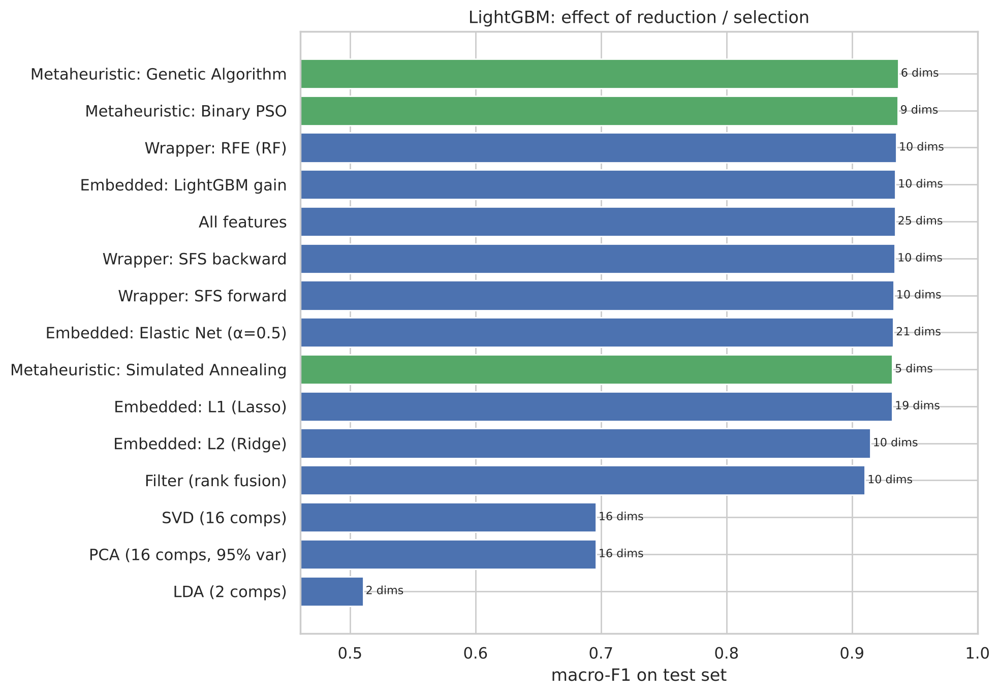

In [28]:
def best_model_clone():
    from sklearn.base import clone
    return clone(MODELS[BEST])

rows = []
for name, cols in SUBSETS.items():
    r, _, _ = evaluate(best_model_clone(), X_tr[cols], y_tr, X_te[cols], y_te)
    rows.append({"Input": name, "# dims": len(cols), **r})
for name, tf in [(f"PCA ({k95} comps, 95% var)", PCA(k95, random_state=RS)),
                 (f"SVD ({k95} comps)", TruncatedSVD(k95, random_state=RS)),
                 ("LDA (2 comps)", LinearDiscriminantAnalysis(n_components=2))]:
    Ztr = tf.fit_transform(Xs_tr, y_tr) if "LDA" in name else tf.fit_transform(Xs_tr)
    Zte = tf.transform(Xs_te)
    r, _, _ = evaluate(best_model_clone(), Ztr, y_tr, Zte, y_te)
    rows.append({"Input": name, "# dims": Ztr.shape[1], **r})
sub_tbl = pd.DataFrame(rows).set_index("Input").sort_values("F1", ascending=False)
display(sub_tbl.round(4))
RESULTS["subset_eval"] = sub_tbl.round(4).reset_index().to_dict(orient="records")

plt.figure(figsize=(10, 7))
s = sub_tbl.sort_values("F1")
bars = plt.barh(s.index, s["F1"], color=["#55A868" if "Metaheur" in i else "#4C72B0" for i in s.index])
for b, d in zip(bars, s["# dims"]): plt.text(b.get_width() + .002, b.get_y() + b.get_height() / 2, f"{d} dims", va="center", fontsize=8)
plt.xlim(s["F1"].min() - .05, 1); plt.xlabel("macro-F1 on test set"); plt.title(f"{BEST}: effect of reduction / selection")
savefig("16_subset_comparison")

## 10. Comparison with Related Work

Published studies on the same Walmart data treat it as **regression**, so their numbers are not directly comparable with our classification metrics.
The table compares *approaches* and what each study reports.

In [29]:
related = pd.DataFrame([
    ["Chen (2022), FFIT/EAI", "Regression (store-level)", "MLR, Elastic-Net, Polynomial",
     "None (manual)", "MLR R²=0.933; ENR R²=0.814"],
    ["Akande et al. (2022), LNEE 881", "Regression", "XGBoost", "Not reported", "XGBoost judged effective"],
    ["Yao (2023), HBEM 5", "Regression (dept-level)", "DT, RF, KNN regressors", "None",
     "RF R²=0.937, MAE=1937.8"],
    ["Chenwi et al. (2024)", "Regression", "LR, RF, GBM, XGBoost, LightGBM", "None", "XGBoost MAE=1226.5, R²≈0.9999"],
    ["Punati et al. (2025), arXiv", "Multi-horizon forecasting (store-level)", "XGB, CNN, LSTM, CNN-LSTM, TFT",
     "None", "TFT R²=0.9875, SMAPE 4.51%"],
    ["This work", "3-class sales-level classification (dept-level)",
     "9 classifiers + 10 reduction + 4 selection families (GA/BPSO/SA)",
     "Filter, wrapper, embedded, GA, BPSO, SA",
     f"{BEST}: acc={HOLD[BEST]['Test acc']:.3f}, F1={HOLD[BEST]['F1']:.3f}, AUC={HOLD[BEST]['ROC-AUC']:.3f}"],
], columns=["Study", "Task", "Models", "Feature selection / reduction", "Best reported result"])
display(related)
RESULTS["related"] = related.to_dict(orient="records")

,Study,Task,Models,Feature selection / reduction,Best reported result
0,"Chen (2022), FFIT/EAI",Regression (store-level),"MLR, Elastic-Net, Polynomial",None (manual),MLR R²=0.933; ENR R²=0.814
1,"Akande et al. (2022), LNEE 881",Regression,XGBoost,Not reported,XGBoost judged effective
2,"Yao (2023), HBEM 5",Regression (dept-level),"DT, RF, KNN regressors",None,"RF R²=0.937, MAE=1937.8"
3,Chenwi et al. (2024),Regression,"LR, RF, GBM, XGBoost, LightGBM",None,"XGBoost MAE=1226.5, R²≈0.9999"
4,"Punati et al. (2025), arXiv",Multi-horizon forecasting (store-level),"XGB, CNN, LSTM, CNN-LSTM, TFT",None,"TFT R²=0.9875, SMAPE 4.51%"
5,This work,3-class sales-level classification (dept-level),9 classifiers + 10 reduction + 4 selection fam...,"Filter, wrapper, embedded, GA, BPSO, SA","LightGBM: acc=0.934, F1=0.934, AUC=0.991"


In [30]:
with open(f"{RES_DIR}/phase1_results.json", "w") as f:
    json.dump(RESULTS, f, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("Saved", f"{RES_DIR}/phase1_results.json", "and", len(os.listdir(FIG_DIR)), "figures in", FIG_DIR)

Saved results/phase1_results.json and 17 figures in figures/phase1


## 11. Conclusions

* **Gradient boosting wins**: LightGBM reaches ≈93.4% accuracy, macro-F1 ≈0.934 and ROC-AUC ≈0.991 (hold-out and 5-fold CV agree within 0.1 pt). XGBoost is a close second.
* **Linear / distance-based models under-fit** (≈44–51% accuracy) because `Dept` and `Store` are identifiers whose effect on sales is non-linear.
* **Default Random Forest / Extra Trees under-perform** a single tree; the ablation in 9.5b shows this is caused by `max_features="sqrt"` hiding the dominant `Dept` feature.
* **Unsupervised 2-D embeddings** keep neighbourhoods (t-SNE/UMAP trustworthiness ≈0.99) but not the sales classes; supervised LDA is the most class-aware 2-D view, and K-Means does not recover the sales levels (ARI ≈0).
* **Selection before reduction** (GA subset of 6 features) raises the kNN accuracy of PCA, t-SNE and UMAP embeddings by about 11–13 points.
* **Metaheuristic selection** gives the best accuracy–size trade-off: the GA keeps 6 of 25 features and slightly *improves* the LightGBM test F1 over using all features.